# Importações

In [ ]:
import warnings
import itertools

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf   
from xgboost import XGBRegressor

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from scipy.stats import jarque_bera, probplot

import matplotlib.animation as animation
from IPython.display import Image, display
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore", category=FutureWarning)

In [212]:
import warnings
from statsmodels.tools.sm_exceptions import (
    ValueWarning,
    ConvergenceWarning,
)

warnings.filterwarnings(
    "ignore",
    category=ValueWarning,
    module=r"statsmodels\."
)

warnings.filterwarnings(
    "ignore",
    category=ConvergenceWarning,
    module=r"statsmodels\."
)

ASSETS_DIR = Path("../assets")
ASSETS_DIR.mkdir(exist_ok=True)

In [130]:
bcb_data = pd.read_csv('../data/bcb_macro.csv')
bcb_data["reference_month"] = pd.to_datetime(bcb_data["reference_month"])
# bcb_data = bcb_data[bcb_data["reference_month"]>"2018-01-01"]

bcb_data = bcb_data.set_index("reference_month")

In [131]:
TARGET = "concessoes_credito_rural_pf"

# Análise Univariada

## Concessão crédito rural

- Concessões de crédito com recursos direcionados para pessoas físicas - crédito rural total
- Periodicidade Mensal

In [132]:
def plot_series(
    series: pd.Series,
    title: str,
    ylabel: str | None = None,
    figsize: tuple[int, int] = (8, 4),
) -> None:
    """
    Plota uma série temporal.
    """

    series = series.dropna()

    plt.figure(figsize=figsize)

    plt.plot(series)

    plt.title(title)
    plt.xlabel("")

    if ylabel:
        plt.ylabel(ylabel)

    plt.tight_layout()
    plt.show()


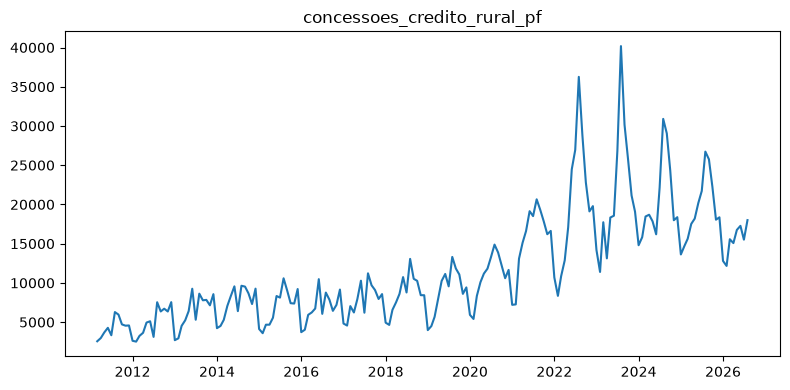

In [133]:
plot_series(
    bcb_data[TARGET],
    TARGET
)

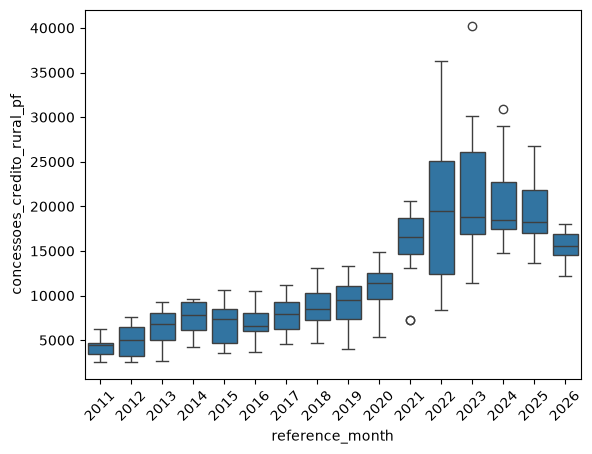

In [134]:
sns.boxplot(
    x=bcb_data[bcb_data[TARGET].notna()].index.year,
    y=TARGET,
    data=bcb_data[bcb_data[TARGET].notna()]
)

plt.xticks(rotation=45)
plt.show()

No momento estamos com o maior indíce de inadimplência pf desde 2011, com cerca de 5,81%, vindo de um aumento expressivo em 2025

### Autocorrelação - ACF

In [ ]:
def plot_acf_series(
    series: pd.Series,
    title: str,
    lags: int = 36,
    figsize: tuple[int, int] = (8, 4),
) -> None:
    """
    Plots the default ACF chart and prints values and confidence intervals.
    """

    series = series.dropna()

    values, confint = acf(
        series,
        nlags=lags,
        alpha=0.05,
        fft=True,
        bartlett_confint=True,
    )

    results = pd.DataFrame({
        "lag": range(len(values)),
        "acf": values,
        "ci_lower": confint[:, 0],
        "ci_upper": confint[:, 1],
    })

    # Confidence intervals in statsmodels' ACF output are centered on
    # the estimated autocorrelation. Convert them to plot-style bounds.
    results["ci_lower_plot"] = results["ci_lower"] - results["acf"]
    results["ci_upper_plot"] = results["ci_upper"] - results["acf"]

    print(f"\n{title} — ACF")
    print(results.to_string(index=False, float_format="%.4f"))

    fig, ax = plt.subplots(figsize=figsize)

    plot_acf(
        series,
        ax=ax,
        lags=lags,
        alpha=0.05,
        fft=True,
        bartlett_confint=True,
    )

    ax.set_title(title)
    plt.tight_layout()
    plt.show()


def plot_pacf_series(
    series: pd.Series,
    title: str,
    lags: int = 36,
    figsize: tuple[int, int] = (8, 4),
) -> None:
    """
    Plots the default PACF chart and prints values and confidence intervals.
    """

    series = series.dropna()

    values, confint = pacf(
        series,
        nlags=lags,
        alpha=0.05,
        method="ywm",
    )

    results = pd.DataFrame({
        "lag": range(len(values)),
        "pacf": values,
        "ci_lower": confint[:, 0],
        "ci_upper": confint[:, 1],
    })

    # Convert confidence intervals to bounds relative to zero,
    # matching the convention used in the default PACF plot.
    results["ci_lower_plot"] = results["ci_lower"] - results["pacf"]
    results["ci_upper_plot"] = results["ci_upper"] - results["pacf"]

    print(f"\n{title} — PACF")
    print(results.to_string(index=False, float_format="%.4f"))

    fig, ax = plt.subplots(figsize=figsize)

    plot_pacf(
        series,
        ax=ax,
        lags=lags,
        alpha=0.05,
        method="ywm",
    )

    ax.set_title(title)
    plt.tight_layout()
    plt.show()

def adf_test(
    series: pd.Series,
) -> None:
    """
    Executa o teste ADF.

    H0: a série possui raiz unitária (não estacionária).
    """

    series = series.dropna()

    result = adfuller(
        series,
        result_object=True,
    )

    print(f"Estatística: {result.statistic:.4f}")
    print(f"p-value: {result.pvalue:.4f}")
    print(f"Lags utilizados: {result.lags}")
    print(f"Observações: {result.nobs}")

    print("\nValores críticos:")

    for key, value in result.critical_values.items():
        print(f"{key}: {value:.4f}")


def kpss_test(
    series: pd.Series,
) -> None:
    """
    Executa o teste KPSS.

    H0: a série é estacionária.
    """

    series = series.dropna()

    result = kpss(
        series,
        result_object=True,
    )

    print("TESTE KPSS")

    print(f"Estatística: {result.statistic:.4f}")
    print(f"p-value: {result.pvalue:.4f}")
    print(f"Lags utilizados: {result.lags}")

    print("\nValores críticos:")

    for key, value in result.critical_values.items():
        print(f"{key}: {value:.4f}")


ACF - concessoes_credito_rural_pf — ACF
 lag    acf  ci_lower  ci_upper  ci_lower_plot  ci_upper_plot
   0 1.0000    1.0000    1.0000         0.0000         0.0000
   1 0.8957    0.7520    1.0394        -0.1437         0.1437
   2 0.7924    0.5605    1.0244        -0.2319         0.2319
   3 0.6842    0.4019    0.9666        -0.2824         0.2824
   4 0.5848    0.2700    0.8995        -0.3148         0.3148
   5 0.5107    0.1743    0.8471        -0.3364         0.3364
   6 0.4911    0.1390    0.8432        -0.3521         0.3521
   7 0.5063    0.1404    0.8723        -0.3660         0.3660
   8 0.5662    0.1861    0.9464        -0.3802         0.3802
   9 0.6330    0.2358    1.0302        -0.3972         0.3972
  10 0.7001    0.2826    1.1176        -0.4175         0.4175
  11 0.7780    0.3369    1.2191        -0.4411         0.4411
  12 0.8488    0.3802    1.3173        -0.4686         0.4686
  13 0.7734    0.2741    1.2728        -0.4993         0.4993
  14 0.6904    0.1669    1.21

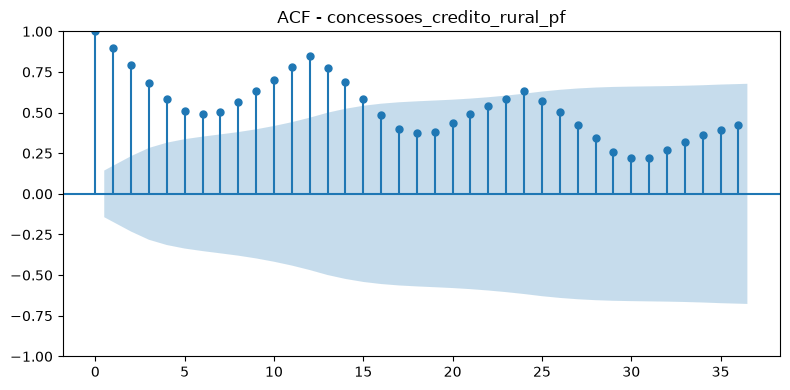

In [136]:
plot_acf_series(
    bcb_data[TARGET],
    f"ACF - {TARGET}"
)


PACF - concessoes_credito_rural_pf — PACF
 lag    pacf  ci_lower  ci_upper  ci_lower_plot  ci_upper_plot
   0  1.0000    1.0000    1.0000         0.0000         0.0000
   1  0.8957    0.7520    1.0394        -0.1437         0.1437
   2 -0.0499   -0.1936    0.0938        -0.1437         0.1437
   3 -0.0826   -0.2263    0.0612        -0.1437         0.1437
   4 -0.0197   -0.1634    0.1240        -0.1437         0.1437
   5  0.0676   -0.0762    0.2113        -0.1437         0.1437
   6  0.2275    0.0838    0.3713        -0.1437         0.1437
   7  0.1673    0.0236    0.3110        -0.1437         0.1437
   8  0.2536    0.1099    0.3973        -0.1437         0.1437
   9  0.1378   -0.0059    0.2815        -0.1437         0.1437
  10  0.1557    0.0120    0.2994        -0.1437         0.1437
  11  0.3104    0.1667    0.4541        -0.1437         0.1437
  12  0.3506    0.2069    0.4943        -0.1437         0.1437
  13 -0.5468   -0.6905   -0.4031        -0.1437         0.1437
  14 -0.0732

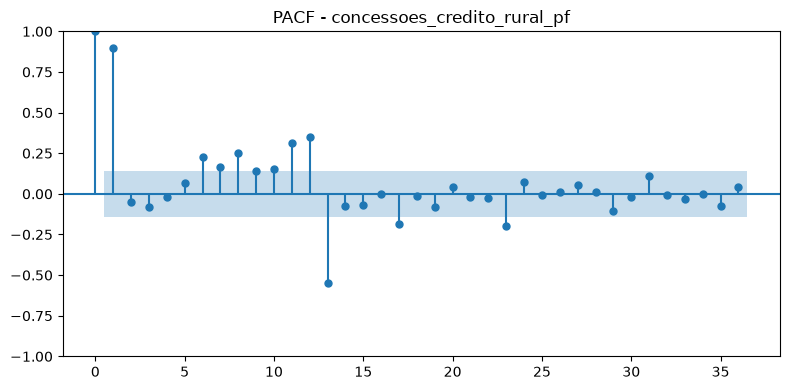

In [137]:
plot_pacf_series(
    bcb_data[TARGET],
    f"PACF - {TARGET}"
)

Série apresenta grande persistência, com sazonalidade aparente de 12 meses

### Transformações

#### Log

Para diminuir a variação da série será aplicado log

In [138]:
bcb_data["log_concessoes_credito_rural_pf"] = np.log(bcb_data[TARGET])

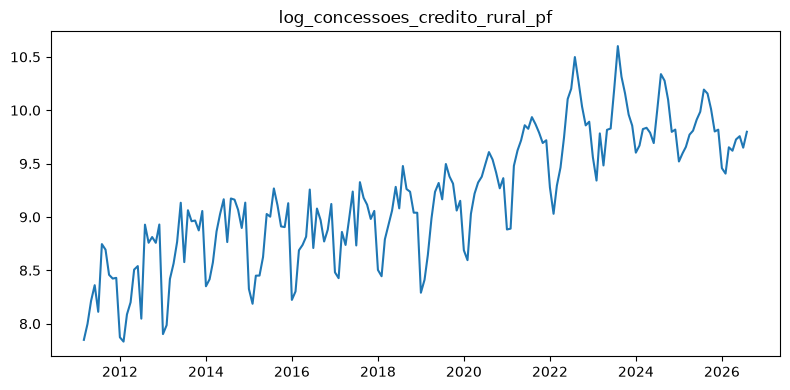

In [139]:
plot_series(
    bcb_data["log_concessoes_credito_rural_pf"],
    "log_concessoes_credito_rural_pf"
)

#### Diferenciação

Diferenciação

$$ \Delta Y_t = Y_t - Y_{t-1} $$

In [140]:
bcb_data["diff_log_concessoes_credito_rural_pf"] = bcb_data["log_concessoes_credito_rural_pf"].diff(1)

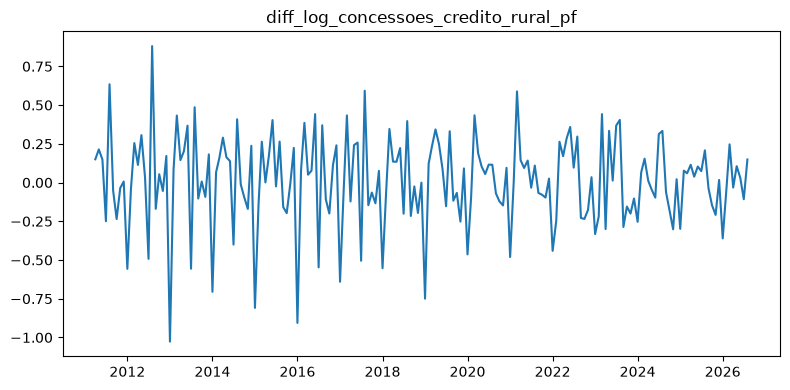

In [141]:
plot_series(
    bcb_data["diff_log_concessoes_credito_rural_pf"],
    "diff_log_concessoes_credito_rural_pf"
)

In [142]:
adf_test(bcb_data["diff_log_concessoes_credito_rural_pf"])

Estatística: -5.5201
p-value: 0.0000
Lags utilizados: 11
Observações: 173

Valores críticos:
1%: -3.4687
5%: -2.8784
10%: -2.5758


In [143]:
kpss_test(bcb_data["diff_log_concessoes_credito_rural_pf"])

TESTE KPSS
Estatística: 0.0191
p-value: 0.1000
Lags utilizados: 1

Valores críticos:
10%: 0.3470
5%: 0.4630
2.5%: 0.5740
1%: 0.7390



ACF - diff_log_concessoes_credito_rural_pf — ACF
 lag     acf  ci_lower  ci_upper  ci_lower_plot  ci_upper_plot
   0  1.0000    1.0000    1.0000         0.0000         0.0000
   1 -0.1710   -0.3151   -0.0269        -0.1441         0.1441
   2 -0.0293   -0.1776    0.1189        -0.1483         0.1483
   3  0.0597   -0.0887    0.2080        -0.1484         0.1484
   4 -0.0851   -0.2340    0.0637        -0.1489         0.1489
   5 -0.3629   -0.5128   -0.2131        -0.1499         0.1499
   6  0.1658   -0.0013    0.3329        -0.1671         0.1671
   7 -0.2927   -0.4633   -0.1222        -0.1705         0.1705
   8 -0.0800   -0.2607    0.1006        -0.1806         0.1806
   9  0.0689   -0.1125    0.2503        -0.1814         0.1814
  10 -0.0468   -0.2287    0.1352        -0.1819         0.1819
  11 -0.1291   -0.3112    0.0531        -0.1822         0.1822
  12  0.8002    0.6161    0.9843        -0.1841         0.1841
  13 -0.1241   -0.3701    0.1218        -0.2459         0.2459
  14 

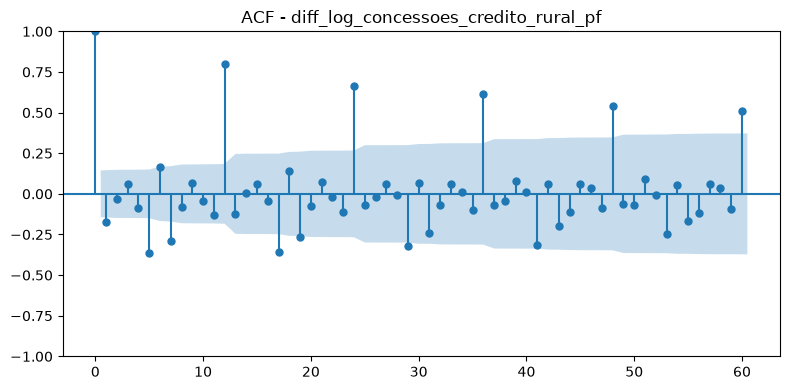

In [144]:
plot_acf_series(
    bcb_data["diff_log_concessoes_credito_rural_pf"],
    f"ACF - diff_log_concessoes_credito_rural_pf",
    lags=60
)


PACF - diff_log_concessoes_credito_rural_pf — PACF
 lag    pacf  ci_lower  ci_upper  ci_lower_plot  ci_upper_plot
   0  1.0000    1.0000    1.0000         0.0000         0.0000
   1 -0.1710   -0.3151   -0.0269        -0.1441         0.1441
   2 -0.0603   -0.2044    0.0838        -0.1441         0.1441
   3  0.0455   -0.0986    0.1896        -0.1441         0.1441
   4 -0.0707   -0.2148    0.0734        -0.1441         0.1441
   5 -0.4016   -0.5456   -0.2575        -0.1441         0.1441
   6  0.0184   -0.1257    0.1625        -0.1441         0.1441
   7 -0.3402   -0.4843   -0.1961        -0.1441         0.1441
   8 -0.2343   -0.3784   -0.0902        -0.1441         0.1441
   9 -0.1905   -0.3346   -0.0464        -0.1441         0.1441
  10 -0.3679   -0.5120   -0.2238        -0.1441         0.1441
  11 -0.5236   -0.6677   -0.3795        -0.1441         0.1441
  12  0.5337    0.3896    0.6778        -0.1441         0.1441
  13  0.0642   -0.0799    0.2083        -0.1441         0.1441
  1

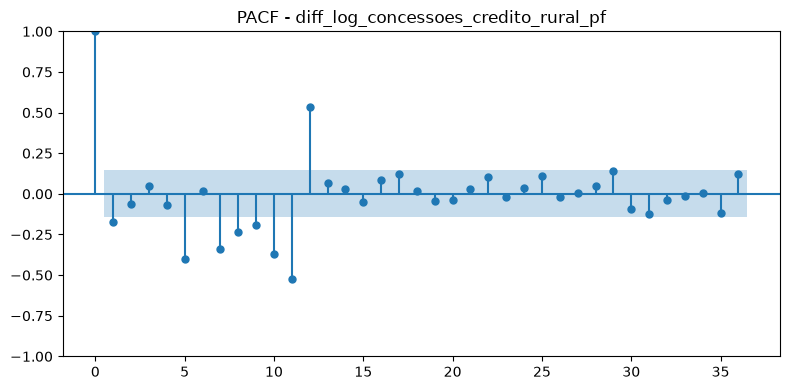

In [145]:
plot_pacf_series(
    bcb_data["diff_log_concessoes_credito_rural_pf"],
    "PACF - diff_log_concessoes_credito_rural_pf"
)

A primeira diferenciação reduziu substancialmente a persistência da série, porém os testes de estacionariedade apresentaram evidências não totalmente convergentes. ADF ficou dentro dos 10% enquando o KPSS ficou dentro dos 5%.

Para evitar mais uma diferenciação, e manter a maior quantidade de informação possível, será utilizado a primeira diferenciação para testes

# Modelagem

## Configurações

In [146]:
warnings.filterwarnings("ignore")

# Target
TARGET = "concessoes_credito_rural_pf"
USE_LOG = True

# Forecasting
HORIZON = 12
FINAL_TEST_SIZE = 12

# Backtesting
INITIAL_TRAIN_SIZE = 72
MIN_TRAIN_SIZE = 72
BACKTEST_STEP = 3
STEP = 3

# Target features
TARGET_LAGS = [1, 3, 6, 12, 15, 18]
ROLLING_WINDOWS = [3, 6, 12]

# Exogenous features
EXOG_CANDIDATES = [
    "selic",
    "ipca",
    "atividade_economica",
    "dolar_venda",
]

EXOG_LAGS = [1, 3, 6, 12, 15, 18]

# Feature selection
MAX_FEATURES = 10
RIDGE_ALPHAS = [0.1, 1.0, 10.0, 100.0]

# XGBoost
XGBOOST_PARAMS = {
    "n_estimators": 200,
    "max_depth": 2,
    "learning_rate": 0.03,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "objective": "reg:squarederror",
    "random_state": 42,
    "n_jobs": -1,
}

# Metrics
HALF_LIFE_WEIGHTED = 24
METRIC = "Weighted_RMSE" # "Weighted_RMSE" "MAE" "RMSE"

## Tratamento dos dados

In [147]:
df = bcb_data[[TARGET] + EXOG_CANDIDATES].copy()

# Standardize monthly index
df.index = pd.to_datetime(df.index).to_period("M").to_timestamp()

# Keep one observation per month and sort chronologically
df = df.groupby(level=0).last().sort_index()
df = df.resample("MS").last()

# Convert columns to numeric
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")

df[EXOG_CANDIDATES] = (
    df[EXOG_CANDIDATES]
    .apply(pd.to_numeric, errors="coerce")
    .ffill()
)

# Keep months with an observed target
df = df.dropna(subset=[TARGET])

In [148]:
# Limites usados exclusivamente na avaliação
test_start = df.index[-FINAL_TEST_SIZE]

print(f"Início da série: {df.index.min():%Y-%m}")
print(f"Início do teste: {test_start:%Y-%m}")
print(f"Fim da série:    {df.index.max():%Y-%m}")

Início da série: 2011-03
Início do teste: 2025-09
Fim da série:    2026-08


In [149]:
# Target lags
for lag in TARGET_LAGS:
    df[f"{TARGET}_lag_{lag}"] = df[TARGET].shift(lag)

# Rolling statistics using past observations only
for window in ROLLING_WINDOWS:
    df[f"{TARGET}_rolling_mean_{window}"] = (
        df[TARGET]
        .shift(1)
        .rolling(window=window)
        .mean()
    )

# Exogenous lags
for col in EXOG_CANDIDATES:
    for lag in EXOG_LAGS:
        df[f"{col}_lag_{lag}"] = df[col].shift(lag)

df

,concessoes_credito_rural_pf,selic,ipca,atividade_economica,dolar_venda,concessoes_credito_rural_pf_lag_1,concessoes_credito_rural_pf_lag_3,concessoes_credito_rural_pf_lag_6,concessoes_credito_rural_pf_lag_12,concessoes_credito_rural_pf_lag_15,...,atividade_economica_lag_6,atividade_economica_lag_12,atividade_economica_lag_15,atividade_economica_lag_18,dolar_venda_lag_1,dolar_venda_lag_3,dolar_venda_lag_6,dolar_venda_lag_12,dolar_venda_lag_15,dolar_venda_lag_18
reference_month,,,,,,,,,,,,,,,,,,,,,
2011-03-01,2562.0,0.92,0.79,101.32049,1.659100,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-04-01,2977.0,0.84,0.77,97.79072,1.586447,2562.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1.659100,NaN,NaN,NaN,NaN,NaN
2011-05-01,3687.0,0.99,0.47,100.13019,1.613491,2977.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1.586447,NaN,NaN,NaN,NaN,NaN
2011-06-01,4277.0,0.96,0.15,99.09338,1.587043,3687.0,2562.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1.613491,1.659100,NaN,NaN,NaN,NaN
2011-07-01,3332.0,0.97,0.16,101.50248,1.563938,4277.0,2977.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1.587043,1.586447,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-04-01,15075.0,1.09,0.67,114.15920,5.033075,15568.0,12802.0,22254.0,17521.0,13628.0,...,110.04186,112.60116,102.62290,109.19299,5.231586,5.338024,5.385526,5.783675,6.021773,5.624109
2026-05-01,16756.0,1.07,0.58,109.79468,4.983700,15075.0,12166.0,18057.0,18197.0,14717.0,...,106.57840,108.58229,106.79048,105.49378,5.033075,5.200617,5.340853,5.667386,5.765645,5.807058
2026-06-01,17274.0,1.12,0.16,110.18456,5.127571,16756.0,15568.0,18361.0,20177.0,15623.0,...,107.19091,107.40511,113.99468,104.15073,4.983700,5.231586,5.453091,5.547055,5.746811,6.097029


In [150]:
dev = df.iloc[:-FINAL_TEST_SIZE].copy()
test = df.iloc[-FINAL_TEST_SIZE:].copy()

print(f"Período completo: {df.index.min():%Y-%m} a {df.index.max():%Y-%m}")
print(f"Desenvolvimento:  {dev.index.min():%Y-%m} a {dev.index.max():%Y-%m}")
print(f"Teste final:      {test.index.min():%Y-%m} a {test.index.max():%Y-%m}")

print(f"\nObservações totais: {len(df)}")
print(f"Observações de desenvolvimento: {len(dev)}")
print(f"Observações de teste: {len(test)}")

Período completo: 2011-03 a 2026-08
Desenvolvimento:  2011-03 a 2025-08
Teste final:      2025-09 a 2026-08

Observações totais: 186
Observações de desenvolvimento: 174
Observações de teste: 12


In [151]:
print("Desenvolvimento")
display(dev.head())
display(dev.tail())

print("\nValores ausentes no desenvolvimento")
display(dev.isna().sum())

print("\nValores ausentes no teste")
display(test.isna().sum())

print("\nEstatísticas da variável-alvo")
display(df[TARGET].describe())

Desenvolvimento


,concessoes_credito_rural_pf,selic,ipca,atividade_economica,dolar_venda,concessoes_credito_rural_pf_lag_1,concessoes_credito_rural_pf_lag_3,concessoes_credito_rural_pf_lag_6,concessoes_credito_rural_pf_lag_12,concessoes_credito_rural_pf_lag_15,...,atividade_economica_lag_6,atividade_economica_lag_12,atividade_economica_lag_15,atividade_economica_lag_18,dolar_venda_lag_1,dolar_venda_lag_3,dolar_venda_lag_6,dolar_venda_lag_12,dolar_venda_lag_15,dolar_venda_lag_18
reference_month,,,,,,,,,,,,,,,,,,,,,
2011-03-01,2562.0,0.92,0.79,101.32049,1.659100,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-04-01,2977.0,0.84,0.77,97.79072,1.586447,2562.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1.659100,NaN,NaN,NaN,NaN,NaN
2011-05-01,3687.0,0.99,0.47,100.13019,1.613491,2977.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1.586447,NaN,NaN,NaN,NaN,NaN
2011-06-01,4277.0,0.96,0.15,99.09338,1.587043,3687.0,2562.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1.613491,1.659100,NaN,NaN,NaN,NaN
2011-07-01,3332.0,0.97,0.16,101.50248,1.563938,4277.0,2977.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1.587043,1.586447,NaN,NaN,NaN,NaN


,concessoes_credito_rural_pf,selic,ipca,atividade_economica,dolar_venda,concessoes_credito_rural_pf_lag_1,concessoes_credito_rural_pf_lag_3,concessoes_credito_rural_pf_lag_6,concessoes_credito_rural_pf_lag_12,concessoes_credito_rural_pf_lag_15,...,atividade_economica_lag_6,atividade_economica_lag_12,atividade_economica_lag_15,atividade_economica_lag_18,dolar_venda_lag_1,dolar_venda_lag_3,dolar_venda_lag_6,dolar_venda_lag_12,dolar_venda_lag_15,dolar_venda_lag_18
reference_month,,,,,,,,,,,,,,,,,,,,,
2025-04-01,17521.0,1.06,0.43,112.60116,5.783675,15623.0,13628.0,24324.0,18689.0,14805.0,...,109.19299,109.26273,99.30433,101.94034,5.746811,6.021773,5.624109,5.129095,4.914395,5.064843
2025-05-01,18197.0,1.14,0.26,108.58229,5.667386,17521.0,14717.0,17988.0,17848.0,15826.0,...,105.49378,104.70903,102.15308,101.67978,5.783675,5.765645,5.807058,5.133048,4.964389,4.898340
2025-06-01,20177.0,1.10,0.24,107.40511,5.547055,18197.0,15623.0,18377.0,16194.0,18464.0,...,104.15073,105.86342,109.56238,101.67778,5.667386,5.746811,6.097029,5.388975,4.980135,4.897245
2025-07-01,21718.0,1.28,0.26,113.20021,5.528491,20177.0,17521.0,13628.0,22140.0,18689.0,...,102.62290,111.51644,109.26273,99.30433,5.547055,5.783675,6.021773,5.542048,5.129095,4.914395
2025-08-01,26733.0,1.16,-0.11,110.38311,5.446924,21718.0,18197.0,14717.0,30901.0,17848.0,...,106.79048,110.06495,104.70903,102.15308,5.528491,5.667386,5.765645,5.552614,5.133048,4.964389



Valores ausentes no desenvolvimento


concessoes_credito_rural_pf                     0
selic                                           0
ipca                                            0
atividade_economica                             0
dolar_venda                                     0
concessoes_credito_rural_pf_lag_1               1
concessoes_credito_rural_pf_lag_3               3
concessoes_credito_rural_pf_lag_6               6
concessoes_credito_rural_pf_lag_12             12
concessoes_credito_rural_pf_lag_15             15
concessoes_credito_rural_pf_lag_18             18
concessoes_credito_rural_pf_rolling_mean_3      3
concessoes_credito_rural_pf_rolling_mean_6      6
concessoes_credito_rural_pf_rolling_mean_12    12
selic_lag_1                                     1
selic_lag_3                                     3
selic_lag_6                                     6
selic_lag_12                                   12
selic_lag_15                                   15
selic_lag_18                                   18



Valores ausentes no teste


concessoes_credito_rural_pf                    0
selic                                          0
ipca                                           0
atividade_economica                            0
dolar_venda                                    0
concessoes_credito_rural_pf_lag_1              0
concessoes_credito_rural_pf_lag_3              0
concessoes_credito_rural_pf_lag_6              0
concessoes_credito_rural_pf_lag_12             0
concessoes_credito_rural_pf_lag_15             0
concessoes_credito_rural_pf_lag_18             0
concessoes_credito_rural_pf_rolling_mean_3     0
concessoes_credito_rural_pf_rolling_mean_6     0
concessoes_credito_rural_pf_rolling_mean_12    0
selic_lag_1                                    0
selic_lag_3                                    0
selic_lag_6                                    0
selic_lag_12                                   0
selic_lag_15                                   0
selic_lag_18                                   0
ipca_lag_1          


Estatísticas da variável-alvo


count      186.000000
mean     11558.327957
std       7064.300077
min       2520.000000
25%       6361.000000
50%       9348.000000
75%      16102.000000
max      40178.000000
Name: concessoes_credito_rural_pf, dtype: float64

In [152]:
# Original target
y_original = df[TARGET].astype(float)

# Transformed target
y_model = (
    np.log1p(y_original)
    if USE_LOG
    else y_original.copy()
)

# Exogenous variables
exog_all = df[EXOG_CANDIDATES].copy()

# Development data
y_dev = y_model.loc[dev.index]
y_dev_original = y_original.loc[dev.index]
exog_dev = exog_all.loc[dev.index]

# Final test data
y_test = y_model.loc[test.index]
y_test_original = y_original.loc[test.index]
exog_test = exog_all.loc[test.index]

### Transformações

In [153]:
def transform_target(y: pd.Series) -> pd.Series:
    """Transform the target for model fitting."""

    if USE_LOG:
        return np.log1p(y.clip(lower=0))

    return y.copy()


def inverse_target(y: pd.Series | np.ndarray) -> np.ndarray:
    """Return model predictions to the original target scale."""

    values = np.asarray(y, dtype=float)

    if USE_LOG:
        values = np.expm1(values)

    # Concessions cannot be negative.
    return np.clip(values, 0, None)


y_original = df[TARGET].astype(float)
y_model = transform_target(y_original)

exog_all = df[EXOG_CANDIDATES].astype(float)

print("Original target:")
display(y_original.describe())

print("Modeling target:")
display(y_model.describe())

Original target:


count      186.000000
mean     11558.327957
std       7064.300077
min       2520.000000
25%       6361.000000
50%       9348.000000
75%      16102.000000
max      40178.000000
Name: concessoes_credito_rural_pf, dtype: float64

Modeling target:


count    186.000000
mean       9.176984
std        0.607630
min        7.832411
25%        8.758098
50%        9.142988
75%        9.686712
max       10.601100
Name: concessoes_credito_rural_pf, dtype: float64

In [154]:
# def make_feature_frame(
#     y: pd.Series,
#     exog: pd.DataFrame,
# ) -> pd.DataFrame:
#     """Create lagged and rolling features from historical data."""

#     features = pd.DataFrame(index=y.index)

#     # Target lags.
#     for lag in TARGET_LAGS:
#         features[f"target_lag_{lag}"] = y.shift(lag)

#     # Rolling statistics use only observations before time t.
#     past_y = y.shift(1)

#     for window in ROLLING_WINDOWS:
#         features[f"target_rolling_mean_{window}"] = (
#             past_y.rolling(window).mean()
#         )

#         features[f"target_rolling_std_{window}"] = (
#             past_y.rolling(window).std()
#         )

#     # Exogenous variables and their lags.
#     for col in exog.columns:
#         for lag in EXOG_LAGS:
#             features[f"{col}_lag_{lag}"] = (
#                 exog[col].shift(lag)
#             )

#     return features


# df_features = make_feature_frame(
#     y=y_model,
#     exog=exog_all,
# )

# # Keep the original target available for interpretation.
# df_features.insert(0, "target_original", y_original)

# # Keep the transformed target for supervised model fitting.
# df_features.insert(1, "target_model", y_model)

# print("Feature dataset shape:", df_features.shape)
# display(df_features.head())

### Criação das features para cada modelo

### Splits para backtest

In [155]:
FEATURE_COLS = [
    col for col in df.columns
    if col not in [TARGET] + EXOG_CANDIDATES
]

def create_splits(data):
    splits = []

    for origin_pos in range(
        INITIAL_TRAIN_SIZE,
        len(data) + 1,
        STEP,
    ):
        train = data.iloc[:origin_pos].copy()

        if train.empty:
            continue

        origin_date = train.index[-1]

        forecast_dates = pd.date_range(
            start=origin_date + pd.offsets.MonthBegin(1),
            periods=HORIZON,
            freq="MS",
        )

        actual = data[TARGET].reindex(forecast_dates)

        splits.append({
            "origin": origin_date,
            "train": train,
            "forecast_dates": forecast_dates,
            "actual": actual,
        })

    return splits


splits = create_splits(df)

print(f"Total de splits: {len(splits)}")
print(f"Última origem: {splits[-1]['origin']:%Y-%m}")
print(f"Última data prevista: {splits[-1]['forecast_dates'][-1]:%Y-%m}")

Total de splits: 39
Última origem: 2026-08
Última data prevista: 2027-08


## Fit e Forecasts

### Naive

In [156]:
def fit_naive(train):
    return {"last_value": train[TARGET].iloc[-1]}


def forecast_naive(fitted, horizon):
    return np.repeat(fitted["last_value"], horizon)

### Seasonal Naive

In [157]:
def fit_seasonal_naive(train, season=12):
    return {"last_values": train[TARGET].iloc[-season:].to_numpy()}


def forecast_seasonal_naive(fitted, horizon):
    values = fitted["last_values"]
    return np.resize(values, horizon)

### Drift

In [158]:
def fit_drift(train):
    y = train[TARGET].to_numpy()

    return {
        "first_value": y[0],
        "last_value": y[-1],
        "n": len(y),
    }


def forecast_drift(fitted, horizon):
    slope = (
        (fitted["last_value"] - fitted["first_value"])
        / (fitted["n"] - 1)
    )

    return fitted["last_value"] + slope * np.arange(1, horizon + 1)

### SARIMA

In [159]:
def fit_sarima(train, config):
    y = train[TARGET].astype(float)

    if USE_LOG:
        y = np.log1p(y)

    model = SARIMAX(
        y,
        order=config["order"],
        seasonal_order=config["seasonal_order"],
        trend="n",
        enforce_stationarity=False,
        enforce_invertibility=False,
    )    

    return model.fit(disp=False)

def forecast_sarima(fitted, horizon):
    forecast_result = fitted.get_forecast(steps=horizon)

    predicted = forecast_result.predicted_mean
    confidence_interval = forecast_result.conf_int(alpha=0.05)

    lower_95 = confidence_interval.iloc[:, 0]
    upper_95 = confidence_interval.iloc[:, 1]

    # Volta à escala original, conforme a lógica atual do projeto
    predicted = inverse_target(predicted)
    lower_95 = inverse_target(lower_95)
    upper_95 = inverse_target(upper_95)

    return pd.DataFrame({
        "predicted": np.clip(np.asarray(predicted, dtype=float), 0, None),
        "lower_95": np.clip(np.asarray(lower_95, dtype=float), 0, None),
        "upper_95": np.clip(np.asarray(upper_95, dtype=float), 0, None),
    })

### SARIMAX 

In [160]:
def make_future_exog(history, features, base_cols, horizon):
    future_dates = pd.date_range(
        start=history.index[-1] + pd.offsets.MonthBegin(1),
        periods=horizon,
        freq="MS",
    )

    missing = [col for col in base_cols if col not in history.columns]
    if missing:
        raise ValueError(f"Variáveis-base ausentes: {missing}")

    base_history = history[base_cols].copy().ffill()

    future_base = pd.DataFrame(index=future_dates)
    for col in base_cols:
        last_value = base_history[col].dropna()

        if last_value.empty:
            raise ValueError(f"Sem valores históricos para {col}")

        future_base[col] = last_value.iloc[-1]

    combined = pd.concat([base_history, future_base])

    future_X = pd.DataFrame(index=future_dates)

    for feature in features:
        if feature in base_cols:
            future_X[feature] = combined[feature].reindex(future_dates)

        elif "_lag_" in feature:
            base, lag_str = feature.rsplit("_lag_", 1)
            lag = int(lag_str)

            if base not in combined.columns:
                raise ValueError(
                    f"Não foi possível reconstruir {feature}: "
                    f"{base} não está em exog_base."
                )

            future_X[feature] = (
                combined[base].shift(lag).reindex(future_dates)
            )

        else:
            raise ValueError(
                f"Feature futura não reconhecida: {feature}"
            )

    if future_X.isna().any().any():
        raise ValueError("Existem valores ausentes nas exógenas futuras.")

    return future_X[features]

In [161]:
# def select_features_elasticnet(X, y, config):
#     from sklearn.pipeline import make_pipeline
#     from sklearn.preprocessing import StandardScaler
#     from sklearn.linear_model import ElasticNetCV
#     from sklearn.model_selection import TimeSeriesSplit

#     if X.empty:
#         return []

#     # Remove variáveis constantes
#     X = X.loc[:, X.nunique() > 1]

#     if X.empty:
#         return []

#     n_splits = min(3, max(2, len(X) // 20))
#     if len(X) <= n_splits + 1:
#         raise ValueError("Histórico insuficiente para ElasticNet.")

#     selector = make_pipeline(
#         StandardScaler(),
#         ElasticNetCV(
#             l1_ratio=[0.2, 0.5, 0.8, 0.95, 1.0],
#             cv=TimeSeriesSplit(n_splits=n_splits),
#             max_iter=20000,
#         ),
#     )

#     selector.fit(X, y)

#     coefficients = pd.Series(
#         selector[-1].coef_,
#         index=X.columns,
#     )

#     # Ordena por importância absoluta dos coeficientes
#     ranked = coefficients.abs().sort_values(
#         ascending=False
#     ).index.tolist()

#     # Se o ElasticNet zerar todos os coeficientes, usa correlação
#     if coefficients.abs().max() < 1e-8:
#         ranked = (
#             X.corrwith(y)
#             .abs()
#             .sort_values(ascending=False)
#             .dropna()
#             .index.tolist()
#         )

#     # Remove variáveis muito correlacionadas com as já selecionadas
#     threshold = config.get("correlation_threshold", 0.95)
#     selected = []

#     for candidate in ranked:
#         if len(selected) >= config.get("max_preselected", 8):
#             break

#         if not selected:
#             selected.append(candidate)
#             continue

#         correlations = X[selected].corrwith(X[candidate]).abs()

#         if correlations.max() < threshold:
#             selected.append(candidate)

#     return selected

In [162]:
# def select_features_forward(
#     core_data,
#     validation_data,
#     candidates,
#     history_for_future,
#     config,
# ):
#     from statsmodels.tsa.statespace.sarimax import SARIMAX
#     from sklearn.metrics import mean_squared_error

#     order = config["order"]
#     seasonal_order = config["seasonal_order"]
#     base_cols = config["exog_base"]
#     max_features = config.get("max_features", 4)
#     min_improvement = config.get("min_improvement", 0.005)
#     maxiter = config.get("maxiter", 50)

#     def transform_target(values):
#         values = np.asarray(values, dtype=float)
#         if USE_LOG:
#             return np.log1p(np.clip(values, 0, None))
#         return values

#     def inverse_target(values):
#         values = np.asarray(values, dtype=float)
#         if USE_LOG:
#             values = np.expm1(values)
#         return np.clip(values, 0, None)

#     y_core = transform_target(core_data[TARGET])
#     y_val = validation_data[TARGET].to_numpy(dtype=float)

#     def evaluate(features):
#         X_core = core_data[features] if features else None

#         model = SARIMAX(
#             y_core,
#             exog=X_core,
#             order=order,
#             seasonal_order=seasonal_order,
#             trend="n",
#             enforce_stationarity=False,
#             enforce_invertibility=False,
#         )

#         result = model.fit(disp=False, maxiter=maxiter)

#         if features:
#             X_future = make_future_exog(
#                 history=history_for_future,
#                 features=features,
#                 base_cols=base_cols,
#                 horizon=len(validation_data),
#             )
#         else:
#             X_future = None

#         prediction = result.forecast(
#             steps=len(validation_data),
#             exog=X_future,
#         )

#         prediction = inverse_target(prediction)

#         return np.sqrt(mean_squared_error(y_val, prediction))

#     selected = []
#     current_rmse = evaluate(selected)

#     remaining = list(candidates)

#     while remaining and len(selected) < max_features:
#         results = []

#         for candidate in remaining:
#             trial_features = selected + [candidate]

#             try:
#                 rmse = evaluate(trial_features)
#                 results.append((candidate, rmse))
#             except Exception as error:
#                 print(f"Forward ignorou {candidate}: {error}")

#         if not results:
#             break

#         best_feature, best_rmse = min(results, key=lambda item: item[1])

#         # Exige uma melhora relativa mínima
#         improvement = (
#             (current_rmse - best_rmse) / current_rmse
#             if current_rmse > 0
#             else 0
#         )

#         if improvement < min_improvement:
#             break

#         selected.append(best_feature)
#         remaining.remove(best_feature)
#         current_rmse = best_rmse

#     return selected

In [163]:
def fit_sarimax(train, config):
    from statsmodels.tsa.statespace.sarimax import SARIMAX

    features = config.get("exog", [])

    missing = [
        col for col in features
        if col not in train.columns
    ]

    if missing:
        raise ValueError(
            f"Variáveis exógenas ausentes: {missing}"
        )

    columns = [TARGET] + features

    data = train[columns].copy()
    data = data.ffill().dropna(subset=columns)

    if len(data) < 36:
        raise ValueError(
            "Histórico insuficiente para ajustar o SARIMAX."
        )

    y = data[TARGET].astype(float)

    if USE_LOG:
        y = np.log1p(y.clip(lower=0))

    X = data[features].astype(float) if features else None

    model = SARIMAX(
        y,
        exog=X,
        order=config["order"],
        seasonal_order=config["seasonal_order"],
        trend="n",
        enforce_stationarity=False,
        enforce_invertibility=False,
    )

    result = model.fit(
        disp=False,
        maxiter=config.get("maxiter", 100),
    )

    if not result.mle_retvals.get("converged", True):
        print("Aviso: o SARIMAX pode não ter convergido.")

    return {
        "result": result,
        "selected_features": features,
        "base_exog": features,
    }

def forecast_sarimax(fitted, train, horizon):
    selected = fitted["selected_features"]
    result = fitted["result"]

    if selected:
        future_X = make_future_exog(
            history=train,
            features=selected,
            base_cols=fitted["base_exog"],
            horizon=horizon,
        )
    else:
        future_X = None

    forecast_result = result.get_forecast(
        steps=horizon,
        exog=future_X,
    )

    prediction = np.asarray(
        forecast_result.predicted_mean,
        dtype=float,
    )

    confidence_interval = forecast_result.conf_int(alpha=0.05)

    lower_95 = np.asarray(confidence_interval.iloc[:, 0], dtype=float)
    upper_95 = np.asarray(confidence_interval.iloc[:, 1], dtype=float)

    # Retorna as previsões e os limites à escala original
    if USE_LOG:
        prediction = np.expm1(prediction)
        lower_95 = np.expm1(lower_95)
        upper_95 = np.expm1(upper_95)

    return pd.DataFrame({
        "predicted": np.clip(prediction, 0, None),
        "lower_95": np.clip(lower_95, 0, None),
        "upper_95": np.clip(upper_95, 0, None),
    })

### ARIMA Errors

In [164]:
def fit_direct_arima_errors(train, horizon, config):
    fitted_models = []
    y_all = transform_target(train[TARGET])

    for h in range(1, horizon + 1):
        training_data = train[FEATURE_COLS].copy()
        training_data["_future_target"] = y_all.shift(-h)

        training_data = training_data.replace(
            [np.inf, -np.inf], np.nan
        ).dropna()

        X = training_data[FEATURE_COLS]
        y_future = training_data["_future_target"]

        # Fallback para janelas com poucas observações
        if len(training_data) < 10:
            fitted_models.append({
                "regression": None,
                "residual_model": None,
                "horizon": h,
            })
            continue

        regression = make_pipeline(
            StandardScaler(),
            RidgeCV(alphas=RIDGE_ALPHAS),
        )

        regression.fit(X, y_future)

        residuals = pd.Series(
            y_future.to_numpy() - regression.predict(X),
            index=training_data.index + pd.DateOffset(months=h),
            dtype=float,
        )

        # ARIMA(1, 0, 0) apenas quando há resíduos suficientes
        if len(residuals) >= 20 and residuals.nunique() > 1:
            residual_model = ARIMA(
                residuals.to_numpy(dtype=float),
                order=config.get("error_order", (1, 0, 0)),
                trend="n",
            ).fit()
        else:
            residual_model = None

        fitted_models.append({
            "regression": regression,
            "residual_model": residual_model,
            "horizon": h,
        })

    return fitted_models

def forecast_direct_arima_errors(fitted, train, horizon):
    X_origin = train[FEATURE_COLS].iloc[[-1]]
    predictions = []

    for h in range(1, horizon + 1):
        item = fitted[h - 1]

        if item["regression"] is None:
            # Sem dados suficientes: usa o último valor observado
            prediction = transform_target(
                train[TARGET].iloc[-1:]
            ).iloc[0]

        else:
            prediction = item["regression"].predict(X_origin)[0]

            if item["residual_model"] is not None:
                residual_prediction = item["residual_model"].forecast(
                    steps=h
                )[-1]

                prediction += residual_prediction

        predictions.append(prediction)

    return inverse_target(np.asarray(predictions))

### XGBoost

In [165]:
def fit_xgboost_direct(train, horizon):
    from xgboost import XGBRegressor

    fitted_models = []

    # Features fixas para todas as janelas e horizontes
    features = [
        col for col in FEATURE_COLS
        if col in train.columns
    ]

    if not features:
        raise ValueError("Nenhuma feature disponível para o XGBoost.")

    for h in range(1, horizon + 1):
        training_data = train[features].copy()

        # Features no mês t -> alvo no mês t+h
        training_data["_future_target"] = (
            train[TARGET].shift(-h)
        )

        # Exclui as últimas h observações sem alvo conhecido
        training_data = training_data.dropna(
            subset=["_future_target"]
        )

        X = training_data[features]
        y = training_data["_future_target"].astype(float)

        valid = np.isfinite(y.to_numpy())
        X = X.loc[valid]
        y = y.loc[valid]

        if len(X) < 36:
            raise ValueError(
                f"Histórico insuficiente para horizonte {h}: "
                f"{len(X)} observações."
            )

        model = XGBRegressor(
            objective="reg:squarederror",
            n_estimators=300,
            learning_rate=0.03,
            max_depth=2,
            min_child_weight=5,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_alpha=0.1,
            reg_lambda=10.0,
            random_state=42,
            n_jobs=-1,
        )

        model.fit(X, y)

        fitted_models.append({
            "model": model,
            "features": features,
            "horizon": h,
        })

    return fitted_models

def forecast_xgboost_direct(fitted, train, horizon):
    predictions = []

    for h in range(horizon):
        item = fitted[h]
        features = item["features"]

        # Última linha disponível na origem da previsão
        X_origin = train[features].iloc[[-1]]

        if X_origin.isna().any().any():
            missing = X_origin.columns[
                X_origin.isna().any()
            ].tolist()

            raise ValueError(
                f"Features ausentes na origem: {missing}"
            )

        prediction = item["model"].predict(X_origin)[0]
        predictions.append(prediction)

    return np.clip(np.asarray(predictions), 0, None)

### ETS

In [166]:
def fit_ets(train, config):
    from statsmodels.tsa.holtwinters import ExponentialSmoothing

    y = transform_target(train[TARGET]).astype(float)
    y = y.replace([np.inf, -np.inf], np.nan).dropna()

    if len(y) < 24:
        raise ValueError("Histórico insuficiente para o ETS.")

    seasonal = config.get("seasonal")
    seasonal_periods = (
        config.get("seasonal_periods", 12)
        if seasonal is not None
        else None
    )

    model = ExponentialSmoothing(
        y,
        trend=config.get("trend"),
        damped_trend=config.get("damped_trend", False),
        seasonal=seasonal,
        seasonal_periods=seasonal_periods,
        initialization_method="estimated",
    )

    result = model.fit(optimized=True)

    return {"result": result}


def forecast_ets(fitted, train, horizon):
    prediction = fitted["result"].forecast(horizon)
    prediction = np.asarray(prediction, dtype=float)

    prediction = inverse_target(prediction)

    return np.clip(np.asarray(prediction), 0, None)

## Modelos Gerais

In [167]:
def fit_direct_ml(train, horizon, config, model_type):
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import RidgeCV
    from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor

    features = [col for col in FEATURE_COLS if col in train.columns]

    if not features:
        raise ValueError("Nenhuma FEATURE_COLS disponível no treino.")

    y_all = transform_target(train[TARGET]).astype(float)

    fitted_models = []

    for h in range(1, horizon + 1):
        data = train[features].copy()
        data["_future_target"] = y_all.shift(-h)

        data = data.replace([np.inf, -np.inf], np.nan)
        data = data.dropna(subset=features + ["_future_target"])

        if len(data) < 36:
            raise ValueError(
                f"Histórico insuficiente para {model_type}, "
                f"horizonte {h}: {len(data)} observações."
            )

        X = data[features]
        y = data["_future_target"].astype(float)

        if model_type == "ridge":
            model = make_pipeline(
                StandardScaler(),
                RidgeCV(
                    alphas=config.get(
                        "alphas", [0.1, 1.0, 10.0, 100.0]
                    )
                ),
            )

        elif model_type == "random_forest":
            model = RandomForestRegressor(
                n_estimators=config.get("n_estimators", 300),
                max_depth=config.get("max_depth", 4),
                min_samples_leaf=config.get("min_samples_leaf", 5),
                max_features=config.get("max_features", 0.8),
                random_state=config.get("random_state", 42),
                n_jobs=config.get("n_jobs", -1),
            )

        elif model_type == "extra_trees":
            model = ExtraTreesRegressor(
                n_estimators=config.get("n_estimators", 300),
                max_depth=config.get("max_depth", 4),
                min_samples_leaf=config.get("min_samples_leaf", 5),
                max_features=config.get("max_features", 0.8),
                random_state=config.get("random_state", 42),
                n_jobs=config.get("n_jobs", -1),
            )

        else:
            raise ValueError(f"Modelo desconhecido: {model_type}")

        model.fit(X, y)

        fitted_models.append({
            "model": model,
            "features": features,
            "horizon": h,
        })

    return fitted_models

def forecast_direct_ml(fitted, train, horizon):
    predictions = []

    for h in range(1, horizon + 1):
        item = fitted[h - 1]
        features = item["features"]

        X_origin = train[features].iloc[[-1]].copy()

        if X_origin.isna().any().any():
            missing = X_origin.columns[
                X_origin.isna().any()
            ].tolist()

            raise ValueError(
                f"Features ausentes na origem, horizonte {h}: {missing}"
            )

        prediction = item["model"].predict(X_origin)[0]
        predictions.append(prediction)

    predictions = inverse_target(np.asarray(predictions, dtype=float))

    return np.clip(np.asarray(predictions), 0, None)

In [168]:
def fit_ridge_direct(train, horizon, config):
    return fit_direct_ml(train, horizon, config, "ridge")


def forecast_ridge_direct(fitted, train, horizon):
    return forecast_direct_ml(fitted, train, horizon)


def fit_random_forest_direct(train, horizon, config):
    return fit_direct_ml(train, horizon, config, "random_forest")


def forecast_random_forest_direct(fitted, train, horizon):
    return forecast_direct_ml(fitted, train, horizon)


def fit_extra_trees_direct(train, horizon, config):
    return fit_direct_ml(train, horizon, config, "extra_trees")


def forecast_extra_trees_direct(fitted, train, horizon):
    return forecast_direct_ml(fitted, train, horizon)

## Treinamento

### Modelos para teste

In [169]:
MODEL_CONFIGS = {
    # =========================================================
    # 1. BASELINES
    # =========================================================
    "Naive": {
        "family": "naive",
    },

    "SeasonalNaive_12": {
        "family": "seasonal_naive",
        "season": 12,
    },

    "Drift": {
        "family": "drift",
    },

    # =========================================================
    # 2. EXPONENTIAL SMOOTHING
    # =========================================================
    "ETS_Additive": {
        "family": "ets",
        "trend": "add",
        "seasonal": None,
        "damped_trend": False,
    },

    "ETS_Seasonal": {
        "family": "ets",
        "trend": "add",
        "seasonal": "add",
        "seasonal_periods": 12,
        "damped_trend": True,
    },

    # =========================================================
    # 3. ARIMA / SARIMA
    # =========================================================
    "ARIMA_111": {
        "family": "sarima",
        "order": (1, 1, 1),
        "seasonal_order": (0, 0, 0, 0),
    },

    "SARIMA_111_101": {
        "family": "sarima",
        "order": (1, 1, 1),
        "seasonal_order": (1, 0, 1, 12),
    },

    "SARIMA_011_011": {
        "family": "sarima",
        "order": (0, 1, 1),
        "seasonal_order": (0, 1, 1, 12),
    },

    # =========================================================
    # 4. SARIMAX: VARIÁVEIS MACROECONÔMICAS
    # =========================================================
    "SARIMAX_Selic": {
        "family": "sarimax",
        "order": (1, 1, 1),
        "seasonal_order": (1, 0, 1, 12),
        "exog": ["selic"],
    },

    "SARIMAX_IPCA": {
        "family": "sarimax",
        "order": (1, 1, 1),
        "seasonal_order": (1, 0, 1, 12),
        "exog": ["ipca"],
    },

    "SARIMAX_Atividade": {
        "family": "sarimax",
        "order": (1, 1, 1),
        "seasonal_order": (1, 0, 1, 12),
        "exog": ["atividade_economica"],
    },

    "SARIMAX_Selic_IPCA": {
        "family": "sarimax",
        "order": (1, 1, 1),
        "seasonal_order": (1, 0, 1, 12),
        "exog": ["selic", "ipca"],
    },

    "SARIMAX_Selic_Atividade": {
        "family": "sarimax",
        "order": (1, 1, 1),
        "seasonal_order": (1, 0, 1, 12),
        "exog": ["selic", "atividade_economica"],
    },

    "SARIMAX_Macro": {
        "family": "sarimax",
        "order": (1, 1, 1),
        "seasonal_order": (1, 0, 1, 12),
        "exog": [
            "selic",
            "ipca",
            "atividade_economica",
        ],
    },

    # =========================================================
    # 5. REGRESSÃO + ARIMA NOS RESÍDUOS
    # =========================================================
    "Direct_ARIMA_Errors": {
        "family": "direct_arima_errors",
        "error_order": (1, 0, 0),
    },

    # =========================================================
    # 6. MACHINE LEARNING: PREVISÃO DIRETA
    # =========================================================
    "RidgeDirect": {
        "family": "ridge_direct",
        "alphas": [0.1, 1.0, 10.0, 100.0],
    },

    "RandomForestDirect": {
        "family": "random_forest_direct",
        "n_estimators": 300,
        "max_depth": 4,
        "min_samples_leaf": 5,
        "max_features": 0.8,
        "random_state": 42,
        "n_jobs": -1,
    },

    "ExtraTreesDirect": {
        "family": "extra_trees_direct",
        "n_estimators": 300,
        "max_depth": 4,
        "min_samples_leaf": 5,
        "max_features": 0.8,
        "random_state": 42,
        "n_jobs": -1,
    },

    "XGBoostDirect": {
        "family": "xgboost_direct",
        "n_estimators": 300,
        "learning_rate": 0.03,
        "max_depth": 2,
        "min_child_weight": 5,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_alpha": 0.1,
        "reg_lambda": 10.0,
        "random_state": 42,
        "n_jobs": -1,
    },
}

In [170]:
def fit_model(config, train, horizon):
    family = config["family"]

    if family == "ets":
        return fit_ets(train, config)

    elif family == "ridge_direct":
        return fit_ridge_direct(train, horizon, config)

    elif family == "random_forest_direct":
        return fit_random_forest_direct(train, horizon, config)

    elif family == "extra_trees_direct":
        return fit_extra_trees_direct(train, horizon, config)

    elif family == "xgboost_direct":
        return fit_xgboost_direct(train, horizon)

    elif family == "direct_arima_errors":
        return fit_direct_arima_errors(train, horizon, config)

    elif family == "sarima":
        return fit_sarima(train, config)

    elif family == "sarimax":
        return fit_sarimax(train, config)

    elif family == "naive":
        return fit_naive(train)

    elif family == "drift":
        return fit_drift(train)

    elif family == "seasonal_naive":
        return fit_seasonal_naive(
            train,
            season=config.get("season", 12)
        )

    else:
        raise ValueError(f"Família de modelo desconhecida: {family}")


def forecast_model(config, fitted, train, horizon):
    family = config["family"]

    if family == "ets":
        return forecast_ets(fitted, train, horizon)

    elif family == "ridge_direct":
        return forecast_ridge_direct(fitted, train, horizon)

    elif family == "random_forest_direct":
        return forecast_random_forest_direct(fitted, train, horizon)

    elif family == "extra_trees_direct":
        return forecast_extra_trees_direct(fitted, train, horizon)

    elif family == "xgboost_direct":
        return forecast_xgboost_direct(fitted, train, horizon)

    elif family == "direct_arima_errors":
        return forecast_direct_arima_errors(fitted, train, horizon)

    elif family == "sarima":
        return forecast_sarima(fitted, horizon)

    elif family == "sarimax":
        return forecast_sarimax(fitted, train, horizon)

    elif family == "naive":
        return forecast_naive(fitted, horizon)

    elif family == "seasonal_naive":
        return forecast_seasonal_naive(fitted, horizon)

    elif family == "drift":
        return forecast_drift(fitted, horizon)

    else:
        raise ValueError(f"Família de modelo desconhecida: {family}")

In [171]:
def get_train_fit_predictions(config, fitted, train):
    """
    Retorna previsões ajustadas dentro do treino.
    Suporta SARIMA e SARIMAX.
    """
    family = config["family"]

    if family == "sarimax":
        result = fitted["result"]
    elif family == "sarima":
        result = fitted
    else:
        # Outras famílias precisam de uma implementação própria.
        return pd.DataFrame(
            columns=["date", "actual", "predicted"]
        )

    predictions = np.asarray(result.fittedvalues).reshape(-1)
    dates = result.model.data.row_labels

    if dates is None:
        dates = train.index[-len(predictions):]

    dates = pd.Index(dates)

    actual = train.loc[dates, TARGET].astype(float)

    # Os modelos foram treinados em log1p?
    if USE_LOG:
        predictions = np.expm1(predictions)

    predictions = np.clip(predictions, 0, None)

    return pd.DataFrame({
        "date": dates,
        "actual": actual.to_numpy(),
        "predicted": predictions,
    }).dropna()

### Backtest

In [172]:
def run_backtest(data, model_configs=MODEL_CONFIGS, verbose=True):
    all_test_results = []
    all_train_results = []
    errors = []

    splits = create_splits(data)

    for split in splits:
        train = split["train"]
        forecast_dates = split["forecast_dates"]
        actual = split["actual"]
        horizon = len(forecast_dates)

        for model_name, config in model_configs.items():
            try:
                # 1. Ajusta o modelo somente com os dados disponíveis
                fitted = fit_model(
                    config=config,
                    train=train,
                    horizon=horizon,
                )

                # 2. Guarda previsões ajustadas no treino, quando disponíveis
                train_fit = get_train_fit_predictions(
                    config=config,
                    fitted=fitted,
                    train=train,
                )

                if train_fit is not None and not train_fit.empty:
                    train_fit = train_fit.copy()
                    train_fit["model"] = model_name
                    train_fit["origin"] = split["origin"]

                    all_train_results.append(train_fit)

                # 3. Gera previsões futuras
                forecast_output = forecast_model(
                    config=config,
                    fitted=fitted,
                    train=train,
                    horizon=horizon,
                )

                # 4. Extrai previsão pontual e intervalos
                if isinstance(forecast_output, pd.DataFrame):
                    if "predicted" not in forecast_output.columns:
                        raise ValueError(
                            "O DataFrame de previsão precisa conter "
                            "a coluna 'predicted'."
                        )

                    predictions = forecast_output[
                        "predicted"
                    ].to_numpy(dtype=float)

                    lower_95 = (
                        forecast_output["lower_95"].to_numpy(dtype=float)
                        if "lower_95" in forecast_output.columns
                        else np.full(horizon, np.nan)
                    )

                    upper_95 = (
                        forecast_output["upper_95"].to_numpy(dtype=float)
                        if "upper_95" in forecast_output.columns
                        else np.full(horizon, np.nan)
                    )

                else:
                    # Compatibilidade com modelos que retornam
                    # apenas array, lista ou Series
                    predictions = np.asarray(
                        forecast_output,
                        dtype=float,
                    ).reshape(-1)

                    lower_95 = np.full(horizon, np.nan)
                    upper_95 = np.full(horizon, np.nan)

                # 5. Valida o tamanho das previsões
                if len(predictions) != horizon:
                    raise ValueError(
                        f"Esperadas {horizon} previsões, "
                        f"mas foram recebidas {len(predictions)}."
                    )

                if len(lower_95) != horizon or len(upper_95) != horizon:
                    raise ValueError(
                        "Os limites dos intervalos não correspondem "
                        "ao horizonte previsto."
                    )

                # 6. Armazena os resultados do split
                fold_results = pd.DataFrame({
                    "model": model_name,
                    "origin": split["origin"],
                    "date": forecast_dates,
                    "actual": actual.to_numpy(),
                    "predicted": predictions,
                    "lower_95": lower_95,
                    "upper_95": upper_95,
                    "horizon": np.arange(1, horizon + 1),
                })

                all_test_results.append(fold_results)

            except Exception as e:
                errors.append({
                    "model": model_name,
                    "origin": split["origin"],
                    "error": str(e),
                })

                if verbose:
                    print(
                        f"Erro em {model_name} | "
                        f"origem {split['origin']:%Y-%m}: {e}"
                    )

    # 7. Verifica se alguma previsão foi gerada
    if not all_test_results:
        errors_df = pd.DataFrame(errors)

        if not errors_df.empty:
            print("\nErros encontrados:")
            print(
                errors_df.groupby(
                    ["model", "error"]
                ).size().reset_index(name="count").to_string(index=False)
            )

        raise ValueError(
            "Nenhuma previsão de teste foi gerada. "
            "Verifique os erros."
        )

    # 8. Consolida previsões de teste
    backtest_results = pd.concat(
        all_test_results,
        ignore_index=True,
    )

    # 9. Consolida resultados de treino
    if all_train_results:
        train_fit_results = pd.concat(
            all_train_results,
            ignore_index=True,
        )
    else:
        train_fit_results = pd.DataFrame(
            columns=[
                "date",
                "actual",
                "predicted",
                "model",
                "origin",
            ]
        )

    errors_df = pd.DataFrame(errors)

    # 10. Resumo da execução
    if verbose:
        print(f"Splits processados: {len(splits)}")
        print(
            f"Previsões de teste geradas: "
            f"{len(backtest_results):,}"
        )
        print(
            f"Ajustes de treino armazenados: "
            f"{len(train_fit_results):,}"
        )
        print(f"Falhas de ajuste/previsão: {len(errors)}")

        if not errors_df.empty:
            print("\nFalhas por modelo:")
            print(
                errors_df.groupby("model")
                .size()
                .sort_values(ascending=False)
                .to_string()
            )

        # Diagnóstico da disponibilidade dos intervalos
        print("\nDisponibilidade dos intervalos:")
        print(
            backtest_results.groupby("model")
            .apply(
                lambda group: pd.Series({
                    "previsoes": len(group),
                    "intervalos_validos": (
                        group["lower_95"].notna()
                        & group["upper_95"].notna()
                    ).sum(),
                }),
                include_groups=False,
            )
            .to_string()
        )

    return backtest_results, train_fit_results, errors_df

In [173]:
backtest_results, train_fit_results, errors_df = run_backtest(
    df,
    model_configs=MODEL_CONFIGS,
)

display(backtest_results.head())
display(train_fit_results.head())

if not errors_df.empty:
    display(errors_df)

Aviso: o SARIMAX pode não ter convergido.
Aviso: o SARIMAX pode não ter convergido.
Aviso: o SARIMAX pode não ter convergido.
Aviso: o SARIMAX pode não ter convergido.
Splits processados: 39
Previsões de teste geradas: 8,892
Ajustes de treino armazenados: 45,279
Falhas de ajuste/previsão: 0

Disponibilidade dos intervalos:
                         previsoes  intervalos_validos
model                                                 
ARIMA_111                      468                 468
Direct_ARIMA_Errors            468                   0
Drift                          468                   0
ETS_Additive                   468                   0
ETS_Seasonal                   468                   0
ExtraTreesDirect               468                   0
Naive                          468                   0
RandomForestDirect             468                   0
RidgeDirect                    468                   0
SARIMAX_Atividade              468                 468
SARIMAX_IPCA   

,model,origin,date,actual,predicted,lower_95,upper_95,horizon
0,Naive,2017-02-01,2017-03-01,7044.0,4567.0,NaN,NaN,1
1,Naive,2017-02-01,2017-04-01,6234.0,4567.0,NaN,NaN,2
2,Naive,2017-02-01,2017-05-01,7941.0,4567.0,NaN,NaN,3
3,Naive,2017-02-01,2017-06-01,10281.0,4567.0,NaN,NaN,4
4,Naive,2017-02-01,2017-07-01,6205.0,4567.0,NaN,NaN,5


,date,actual,predicted,model,origin
0,2011-03-01,2562.0,0.000000,ARIMA_111,2017-02-01
1,2011-04-01,2977.0,15798.791712,ARIMA_111,2017-02-01
2,2011-05-01,3687.0,3191.500768,ARIMA_111,2017-02-01
3,2011-06-01,4277.0,3788.611252,ARIMA_111,2017-02-01
4,2011-07-01,3332.0,4227.522318,ARIMA_111,2017-02-01


### Desempenho

In [174]:
def evaluate_backtest(results, dataset="geral", test_start=None):
    results = results.copy()

    results = results.dropna(subset=["actual", "predicted"])

    if dataset == "treino":
        results = results[results["date"] < test_start]
    elif dataset == "teste":
        results = results[results["date"] >= test_start]
    elif dataset != "geral":
        raise ValueError("dataset deve ser 'treino', 'teste' ou 'geral'")

    rows = []

    for model_name, data in results.groupby("model"):
        errors = data["actual"] - data["predicted"]
        weights = 0.5 ** ((data["horizon"] - 1) / HALF_LIFE_WEIGHTED)

        rows.append({
            "model": model_name,
            "MAE": errors.abs().mean(),
            "RMSE": np.sqrt((errors ** 2).mean()),
            "Weighted_RMSE": np.sqrt(
                np.average(errors ** 2, weights=weights)
            ),
            "N": len(data),
        })

    return pd.DataFrame(rows).sort_values(METRIC).reset_index()

In [175]:
test_start = df.index[-FINAL_TEST_SIZE]

# Avaliar treino
evaluation_train = evaluate_backtest(
    backtest_results,
    dataset="treino",
    test_start=test_start,
)

# Avaliar teste
evaluation_test = evaluate_backtest(
    backtest_results,
    dataset="teste",
    test_start=test_start,
)

# Avaliar geral
evaluation_general = evaluate_backtest(
    backtest_results,
    dataset="geral",
)

print("Treino")
print(evaluation_train.round(4))
print("Teste")
print(evaluation_test.round(4))
print("Total")
print(evaluation_general.round(4))

Treino
    index                    model        MAE        RMSE  Weighted_RMSE    N
0      12            SARIMAX_Selic  2393.3107   3357.7962      3343.9590  390
1      14       SARIMAX_Selic_IPCA  2433.6930   3414.9738      3400.3883  390
2      13  SARIMAX_Selic_Atividade  2463.9062   3428.1194      3410.2154  390
3      10             SARIMAX_IPCA  2439.4336   3524.5044      3485.7484  390
4      11            SARIMAX_Macro  2493.5551   3504.6136      3486.8337  390
5      16           SARIMA_111_101  2438.7429   3575.6265      3537.1233  390
6      17         SeasonalNaive_12  2531.7769   3592.8524      3582.6122  390
7       9        SARIMAX_Atividade  2705.9179   3722.5799      3688.5546  390
8      15           SARIMA_011_011  2688.3815   4171.7476      4125.0768  390
9       4             ETS_Seasonal  2910.2264   4366.7966      4338.9699  390
10     18            XGBoostDirect  3520.0882   5074.5082      5082.4087  390
11      5         ExtraTreesDirect  3637.8112   5331.0819

In [176]:
# 1. Separação temporal
test_start = df.index[-FINAL_TEST_SIZE]

development = df.loc[df.index < test_start].copy()
test = df.loc[df.index >= test_start].copy()

# 2. Selecionar o modelo pelo backtest de desenvolvimento
best_model = evaluation_train.iloc[0]["model"]
config = MODEL_CONFIGS[best_model]

print("Modelo selecionado:", best_model)
print("Último mês de desenvolvimento:", development.index[-1])
print("Primeiro mês de teste:", test.index[0])
print("Último mês de teste:", test.index[-1])

# 3. Ajustar somente com os dados anteriores ao holdout
fitted_final = fit_model(
    config=config,
    train=development,
    horizon=len(test),
)

# 4. Gerar uma única previsão para os 12 meses do holdout
forecast_output = forecast_model(
    config=config,
    fitted=fitted_final,
    train=development,
    horizon=len(test),
)

if isinstance(forecast_output, pd.DataFrame):
    predictions = forecast_output["predicted"].to_numpy(dtype=float)
else:
    predictions = np.asarray(forecast_output, dtype=float).reshape(-1)

# 5. Comparar com os valores observados
holdout_results = pd.DataFrame({
    "actual": test[TARGET].to_numpy(dtype=float),
    "predicted": predictions,
}, index=test.index)

errors = holdout_results["actual"] - holdout_results["predicted"]

weights = 0.5 ** (
    np.arange(len(holdout_results)) / HALF_LIFE_WEIGHTED
)

holdout_metrics = pd.DataFrame([{
    "model": best_model,
    "MAE": errors.abs().mean(),
    "RMSE": np.sqrt((errors ** 2).mean()),
    "Weighted_RMSE": np.sqrt(
        np.average(errors ** 2, weights=weights)
    ),
    "N": len(holdout_results),
}])

print(holdout_metrics.round(2))
print(holdout_results)

Modelo selecionado: SARIMAX_Selic
Último mês de desenvolvimento: 2025-08-01 00:00:00
Primeiro mês de teste: 2025-09-01 00:00:00
Último mês de teste: 2026-08-01 00:00:00
           model      MAE     RMSE  Weighted_RMSE   N
0  SARIMAX_Selic  2038.33  3076.95        2875.52  12
                  actual     predicted
reference_month                       
2025-09-01       25754.0  25287.177454
2025-10-01       22254.0  22039.184374
2025-11-01       18057.0  19137.687061
2025-12-01       18361.0  18547.805046
2026-01-01       12802.0  13807.772570
2026-02-01       12166.0  14362.650951
2026-03-01       15568.0  16529.585955
2026-04-01       15075.0  17027.779707
2026-05-01       16756.0  17769.397933
2026-06-01       17274.0  19089.890003
2026-07-01       15512.0  20675.019340
2026-08-01       18002.0  26403.703582


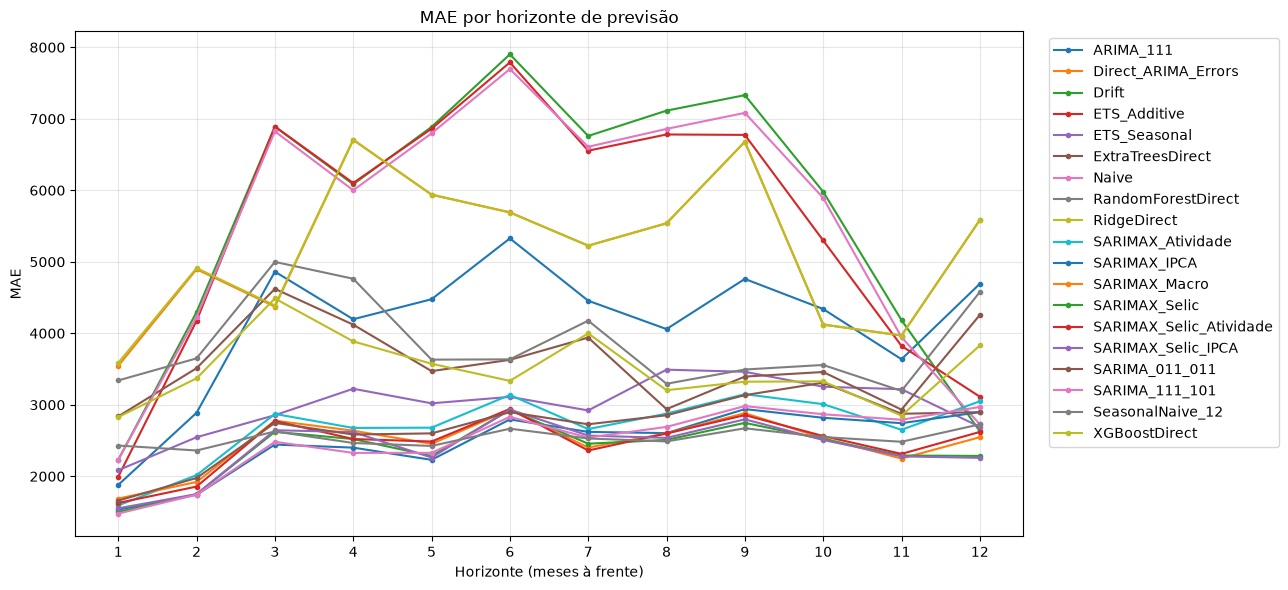

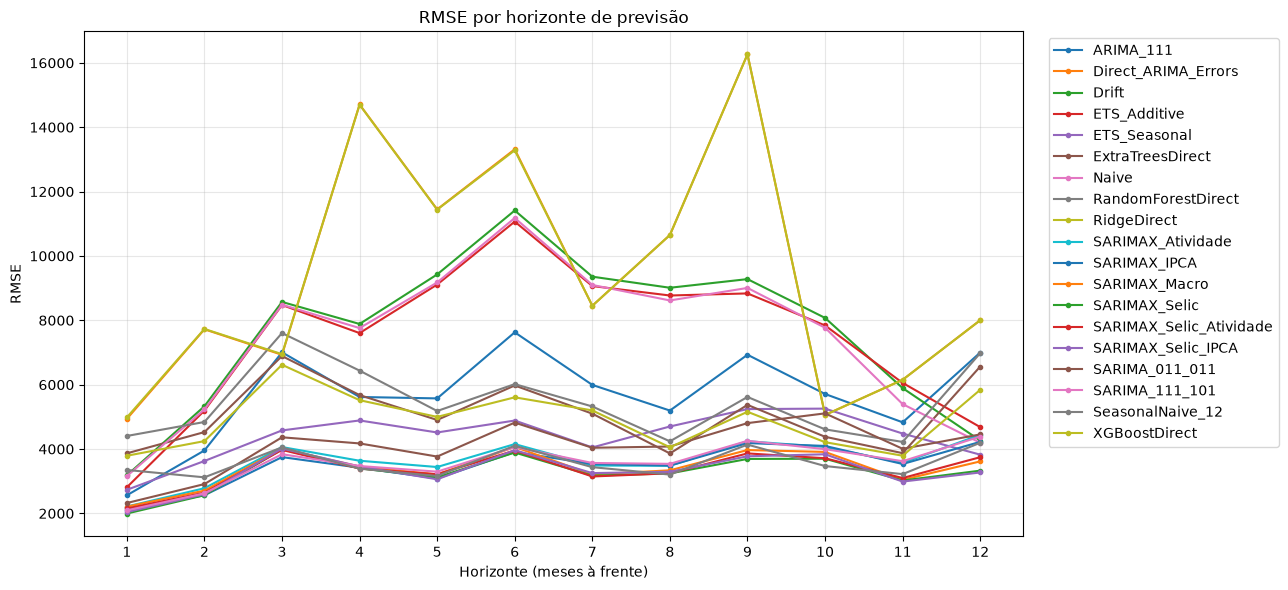

,model,horizon,MAE,MSE,N,RMSE
0,ARIMA_111,1,1879.8278,6.563547e+06,38,2561.9421
1,ARIMA_111,2,2888.6773,1.564486e+07,38,3955.3583
2,ARIMA_111,3,4861.9573,4.907635e+07,38,7005.4512
3,ARIMA_111,4,4196.5748,3.155156e+07,37,5617.0777
4,ARIMA_111,5,4476.3226,3.105843e+07,37,5573.0087
...,...,...,...,...,...,...
223,XGBoostDirect,8,3203.9787,1.643801e+07,36,4054.3813
224,XGBoostDirect,9,3323.2704,2.659707e+07,36,5157.2351
225,XGBoostDirect,10,3327.8011,1.774105e+07,35,4212.0122
226,XGBoostDirect,11,2848.8172,1.437967e+07,35,3792.0533


In [178]:
# Remover previsões sem valor real disponível
results = backtest_results.copy()

results["date"] = pd.to_datetime(results["date"])

results = results.dropna(
    subset=["actual", "predicted", "horizon"]
)

results = results[
    np.isfinite(results["actual"])
    & np.isfinite(results["predicted"])
].copy()

results["error"] = results["actual"] - results["predicted"]
results["absolute_error"] = results["error"].abs()
results["squared_error"] = results["error"] ** 2

# Calcular métricas por modelo e horizonte
horizon_metrics = (
    results.groupby(["model", "horizon"])
    .agg(
        MAE=("absolute_error", "mean"),
        MSE=("squared_error", "mean"),
        N=("error", "count"),
    )
    .reset_index()
)

horizon_metrics["RMSE"] = np.sqrt(horizon_metrics["MSE"])

# Gráfico MAE
plt.figure(figsize=(13, 6))

for model_name, data in horizon_metrics.groupby("model"):
    plt.plot(
        data["horizon"],
        data["MAE"],
        marker="o",
        markersize=3,
        label=model_name,
    )

plt.title("MAE por horizonte de previsão")
plt.xlabel("Horizonte (meses à frente)")
plt.ylabel("MAE")
plt.xticks(sorted(results["horizon"].unique()))
plt.grid(alpha=0.3)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Gráfico RMSE
plt.figure(figsize=(13, 6))

for model_name, data in horizon_metrics.groupby("model"):
    plt.plot(
        data["horizon"],
        data["RMSE"],
        marker="o",
        markersize=3,
        label=model_name,
    )

plt.title("RMSE por horizonte de previsão")
plt.xlabel("Horizonte (meses à frente)")
plt.ylabel("RMSE")
plt.xticks(sorted(results["horizon"].unique()))
plt.grid(alpha=0.3)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

display(horizon_metrics.round(4))


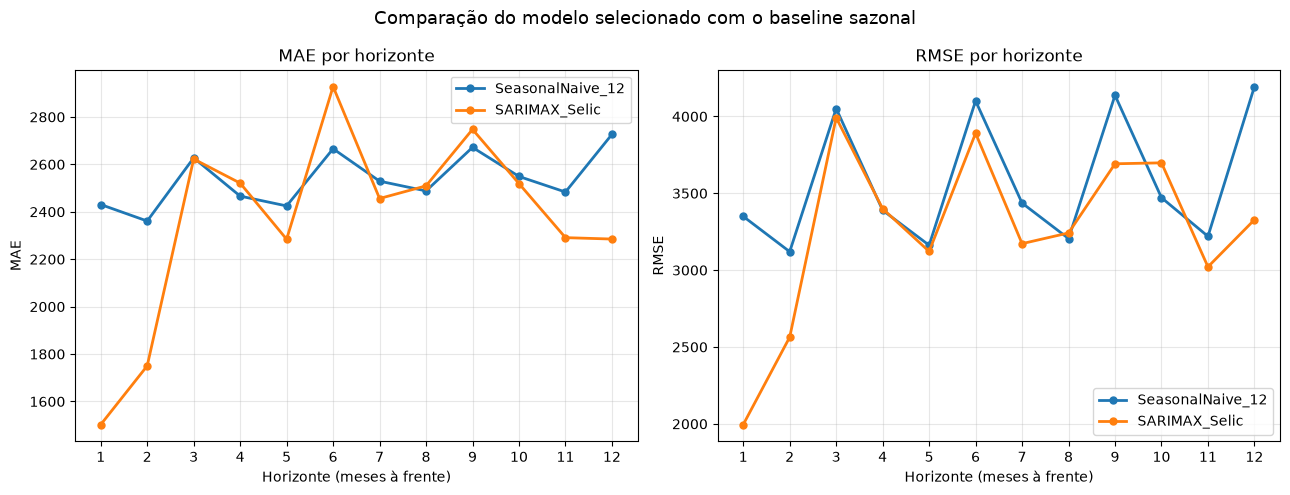

                  MAE                           RMSE                 
model   SARIMAX_Selic SeasonalNaive_12 SARIMAX_Selic SeasonalNaive_12
horizon                                                              
1             1502.46          2430.55       1995.19          3349.68
2             1750.15          2361.00       2564.04          3120.06
3             2622.55          2627.42       3991.61          4051.47
4             2520.91          2466.11       3399.68          3389.69
5             2284.18          2424.70       3121.80          3161.94
6             2928.09          2665.89       3890.52          4101.08
7             2456.00          2529.14       3172.35          3436.29
8             2509.32          2488.00       3241.89          3205.46
9             2747.60          2671.69       3691.88          4137.43
10            2518.81          2548.97       3698.03          3471.21
11            2290.92          2483.31       3021.44          3219.88
12            2285.0

In [213]:
# Modelos para comparação
SELECTED_MODEL = "SARIMAX_Selic"
BASELINE_MODEL = "SeasonalNaive_12"

models_to_plot = [
    BASELINE_MODEL,
    SELECTED_MODEL,
]

plot_data = horizon_metrics[
    horizon_metrics["model"].isin(models_to_plot)
].copy()

if plot_data.empty:
    raise ValueError(
        "Nenhum dos modelos foi encontrado em horizon_metrics. "
        "Confira os nomes em horizon_metrics['model'].unique()."
    )

# Verificar se ambos os modelos estão disponíveis
available_models = plot_data["model"].unique()

if len(available_models) < 2:
    print(
        "Atenção: apenas um dos modelos foi encontrado:",
        available_models
    )

# Gráficos resumidos
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

metrics_to_plot = [
    ("MAE", "MAE por horizonte"),
    ("RMSE", "RMSE por horizonte"),
]

for ax, (metric, title) in zip(axes, metrics_to_plot):
    for model_name in models_to_plot:
        data = (
            plot_data[plot_data["model"] == model_name]
            .sort_values("horizon")
        )

        if not data.empty:
            ax.plot(
                data["horizon"],
                data[metric],
                marker="o",
                linewidth=2,
                markersize=5,
                label=model_name,
            )

    ax.set_title(title)
    ax.set_xlabel("Horizonte (meses à frente)")
    ax.set_ylabel(metric)
    ax.set_xticks(sorted(plot_data["horizon"].unique()))
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle(
    "Comparação do modelo selecionado com o baseline sazonal",
    fontsize=13,
)
plt.tight_layout()
plt.savefig(
    ASSETS_DIR / "horizon_comparation.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print(
    plot_data.pivot(
        index="horizon",
        columns="model",
        values=["MAE", "RMSE"],
    ).round(2)
)

GIF salvo como backtest_previsoes.gif


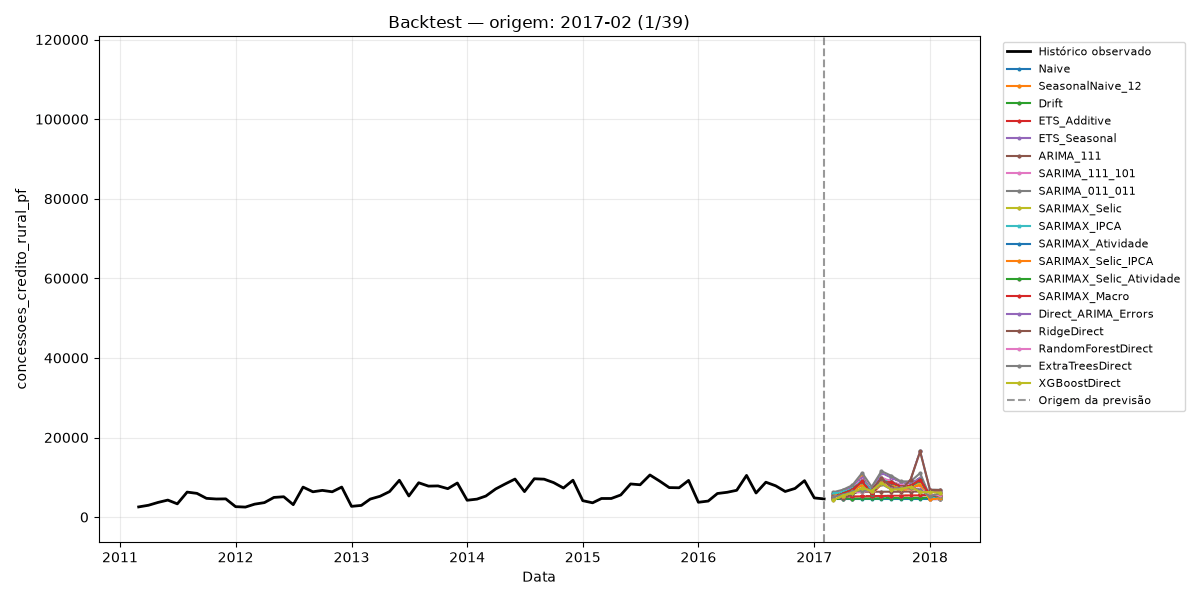

In [179]:
# Série histórica observada
y = df[TARGET].dropna().copy()
y.index = pd.to_datetime(y.index)
y = y.sort_index()

results = backtest_results.copy()
results["date"] = pd.to_datetime(results["date"])
results["origin"] = pd.to_datetime(results["origin"])

models = results["model"].unique()
origins = sorted(results["origin"].unique())

# Mostrar apenas as origens que possuem previsões
origins = [
    origin for origin in origins
    if (results["origin"] == origin).any()
]

# Limites do gráfico para manter a escala constante durante a animação
forecast_values = results["predicted"].dropna().to_numpy()
all_values = np.concatenate([y.to_numpy(), forecast_values])

y_min = np.nanmin(all_values)
y_max = np.nanmax(all_values)
padding = (y_max - y_min) * 0.08 if y_max > y_min else 1

fig, ax = plt.subplots(figsize=(12, 6))

def update(frame):
    ax.clear()

    origin = pd.Timestamp(origins[frame])

    # Histórico conhecido até a origem
    history = y[y.index <= origin]

    ax.plot(
        history.index,
        history.values,
        color="black",
        linewidth=2,
        label="Histórico observado",
    )

    # Previsões de cada modelo naquela origem
    for model_name in models:
        forecast = results[
            (results["model"] == model_name)
            & (results["origin"] == origin)
        ].sort_values("date")

        if forecast.empty:
            continue

        ax.plot(
            forecast["date"],
            forecast["predicted"],
            marker="o",
            markersize=2,
            linewidth=1.5,
            label=model_name,
        )

    # Linha vertical da origem
    ax.axvline(
        origin,
        color="gray",
        linestyle="--",
        alpha=0.8,
        label="Origem da previsão",
    )

    ax.set_title(
        f"Backtest — origem: {origin:%Y-%m} "
        f"({frame + 1}/{len(origins)})"
    )
    ax.set_xlabel("Data")
    ax.set_ylabel(TARGET)
    ax.set_ylim(y_min - padding, y_max + padding)
    ax.grid(alpha=0.25)
    ax.legend(
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
        fontsize=8,
    )

    fig.tight_layout()

ani = animation.FuncAnimation(
    fig,
    update,
    frames=len(origins),
    interval=700,
    repeat=True,
)

ani.save(
    "backtest_previsoes.gif",
    writer=animation.PillowWriter(fps=2),
    dpi=100,
)

plt.close(fig)

print("GIF salvo como backtest_previsoes.gif")
display(Image(filename="backtest_previsoes.gif"))


Melhor modelo: SARIMAX_Selic
Configuração: {'family': 'sarimax', 'order': (1, 1, 1), 'seasonal_order': (1, 0, 1, 12), 'exog': ['selic']}


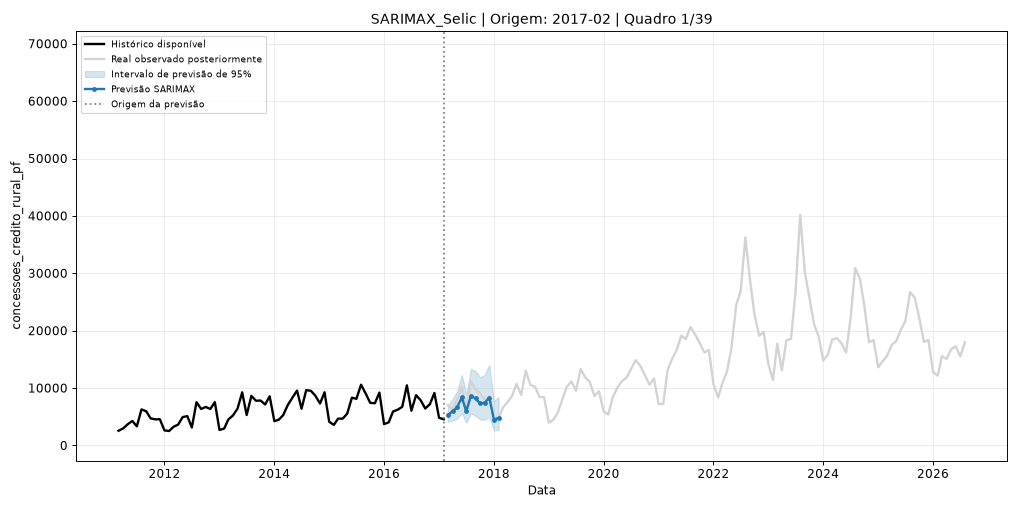

GIF salvo em: F:\Projects\Codes\Arquitetura de Dados\Data Analysis\assets\backtest_forecast.gif


In [207]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.animation as animation

from IPython.display import Image, display
from pathlib import Path

print("Melhor modelo:", best_model)
print("Configuração:", MODEL_CONFIGS[best_model])

y = df[TARGET].dropna().copy()
y.index = pd.to_datetime(y.index)
y = y.sort_index()

results_best = backtest_results.loc[
    backtest_results["model"] == best_model
].copy()

results_best["date"] = pd.to_datetime(results_best["date"])
results_best["origin"] = pd.to_datetime(results_best["origin"])

results_best = results_best.sort_values(["origin", "date"])

required_cols = {"actual", "predicted", "lower_95", "upper_95"}
missing_cols = required_cols - set(results_best.columns)

if missing_cols:
    raise ValueError(
        f"Faltam colunas em backtest_results: {sorted(missing_cols)}. "
        "Armazene os limites do intervalo de previsão no backtest."
    )

origins = sorted(results_best["origin"].dropna().unique())

if not origins:
    raise ValueError("Não há previsões para o modelo selecionado.")

values = np.concatenate([
    y.to_numpy(dtype=float),
    results_best["predicted"].dropna().to_numpy(dtype=float),
    results_best["lower_95"].dropna().to_numpy(dtype=float),
    results_best["upper_95"].dropna().to_numpy(dtype=float),
])

y_min = np.nanmin(values)
y_max = np.nanmax(values)
padding = (y_max - y_min) * 0.08 if y_max > y_min else 1

fig, ax = plt.subplots(figsize=(12, 6))

def update(frame):
    ax.clear()

    origin = pd.Timestamp(origins[frame])

    # Histórico conhecido na origem
    history = y[y.index <= origin]

    ax.plot(
        history.index,
        history.values,
        color="black",
        linewidth=2,
        label="Histórico disponível",
    )

    forecast = (
        results_best.loc[results_best["origin"] == origin]
        .sort_values("date")
        .copy()
    )

    forecast = forecast.dropna(
        subset=["predicted", "lower_95", "upper_95"]
    )

    # Valores reais posteriores: cinza claro, linha contínua
    actual_future = y[y.index > origin]

    if not actual_future.empty:
        ax.plot(
            actual_future.index,
            actual_future.values,
            color="lightgray",
            linestyle="-",
            linewidth=2,
            label="Real observado posteriormente",
        )

    # Intervalo de previsão de 95%
    ax.fill_between(
        forecast["date"],
        forecast["lower_95"],
        forecast["upper_95"],
        color="tab:blue",
        alpha=0.18,
        label="Intervalo de previsão de 95%",
    )

    # Previsão pontual
    ax.plot(
        forecast["date"],
        forecast["predicted"],
        color="tab:blue",
        marker="o",
        markersize=3,
        linewidth=2,
        label="Previsão SARIMAX",
    )

    ax.axvline(
        origin,
        color="gray",
        linestyle=":",
        label="Origem da previsão",
    )

    ax.set_title(
        f"{best_model} | Origem: {origin:%Y-%m} "
        f"| Quadro {frame + 1}/{len(origins)}"
    )
    ax.set_xlabel("Data")
    ax.set_ylabel(TARGET)
    ax.set_ylim(y_min - padding, y_max + padding)
    ax.grid(alpha=0.25)
    ax.legend(loc="upper left", fontsize=8)
    fig.tight_layout()

ani = animation.FuncAnimation(
    fig,
    update,
    frames=len(origins),
    interval=700,
    repeat=True,
)

gif_path =  ASSETS_DIR / "backtest_forecast.gif"

ani.save(
    str(gif_path),
    writer=animation.PillowWriter(fps=2),
    dpi=85,
)

plt.close(fig)

display(Image(filename=str(gif_path)))
print(f"GIF salvo em: {gif_path.resolve()}")

In [189]:
# Modelo selecionado no backtest
model_name = "SARIMAX_Selic"
config = MODEL_CONFIGS[model_name]

target_col = "concessoes_credito_rural_pf"
required_cols = [target_col] + config["exog"]

train_final = (
    df[required_cols]
    .dropna()
    .sort_index()
    .copy()
)

fitted_final = fit_model(
    config=config,
    train=train_final,
    horizon=HORIZON,
)

print(fitted_final["result"].summary())

                                     SARIMAX Results                                      
Dep. Variable:        concessoes_credito_rural_pf   No. Observations:                  186
Model:             SARIMAX(1, 1, 1)x(1, 0, 1, 12)   Log Likelihood                 108.024
Date:                            Mon, 26 Oct 2026   AIC                           -204.048
Time:                                    16:09:02   BIC                           -185.198
Sample:                                03-01-2011   HQIC                          -196.400
                                     - 08-01-2026                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
selic          0.5713      0.114      5.006      0.000       0.348       0.795
ar.L1          0.5971      0.144   

## Erros

### Erros de backtest

In [190]:
model_name = "SARIMAX_Selic"

bt = backtest_results.loc[
    backtest_results["model"].eq(model_name)
].copy()

bt["date"] = pd.to_datetime(bt["date"])
bt["origin"] = pd.to_datetime(bt["origin"])

for col in ["actual", "predicted", "horizon"]:
    bt[col] = pd.to_numeric(bt[col], errors="coerce")

# Excluir previsões sem valor real ou sem previsão válida
bt = bt.dropna(
    subset=["actual", "predicted", "horizon"]
).copy()

# Erro positivo = subestimação; erro negativo = superestimação
bt["error"] = bt["actual"] - bt["predicted"]
bt["abs_error"] = bt["error"].abs()
bt["squared_error"] = bt["error"] ** 2

overall_metrics = pd.Series({
    "N": len(bt),
    "MAE": bt["abs_error"].mean(),
    "RMSE": np.sqrt(bt["squared_error"].mean()),
    "Bias": bt["error"].mean(),
})

print(overall_metrics.round(2))

N        438.00
MAE     2363.85
RMSE    3300.72
Bias    -203.00
dtype: float64


In [191]:
metrics_by_horizon = (
    bt.groupby("horizon")
    .agg(
        N=("error", "size"),
        MAE=("abs_error", "mean"),
        MSE=("squared_error", "mean"),
        Bias=("error", "mean"),
    )
)

metrics_by_horizon["RMSE"] = np.sqrt(
    metrics_by_horizon["MSE"]
)

metrics_by_horizon = metrics_by_horizon.drop(
    columns="MSE"
)

print(metrics_by_horizon.round(2))

          N      MAE    Bias     RMSE
horizon                              
1        38  1502.46 -337.84  1995.19
2        38  1750.15   97.83  2564.04
3        38  2622.55  -36.64  3991.61
4        37  2520.91 -326.24  3399.68
5        37  2284.18  180.75  3121.80
6        37  2928.09   27.61  3890.52
7        36  2456.00 -411.59  3172.35
8        36  2509.32   51.77  3241.89
9        36  2747.60 -296.82  3691.88
10       35  2518.81 -638.21  3698.03
11       35  2290.92 -202.35  3021.44
12       35  2285.02 -599.48  3327.80


### Resíduos do modelo

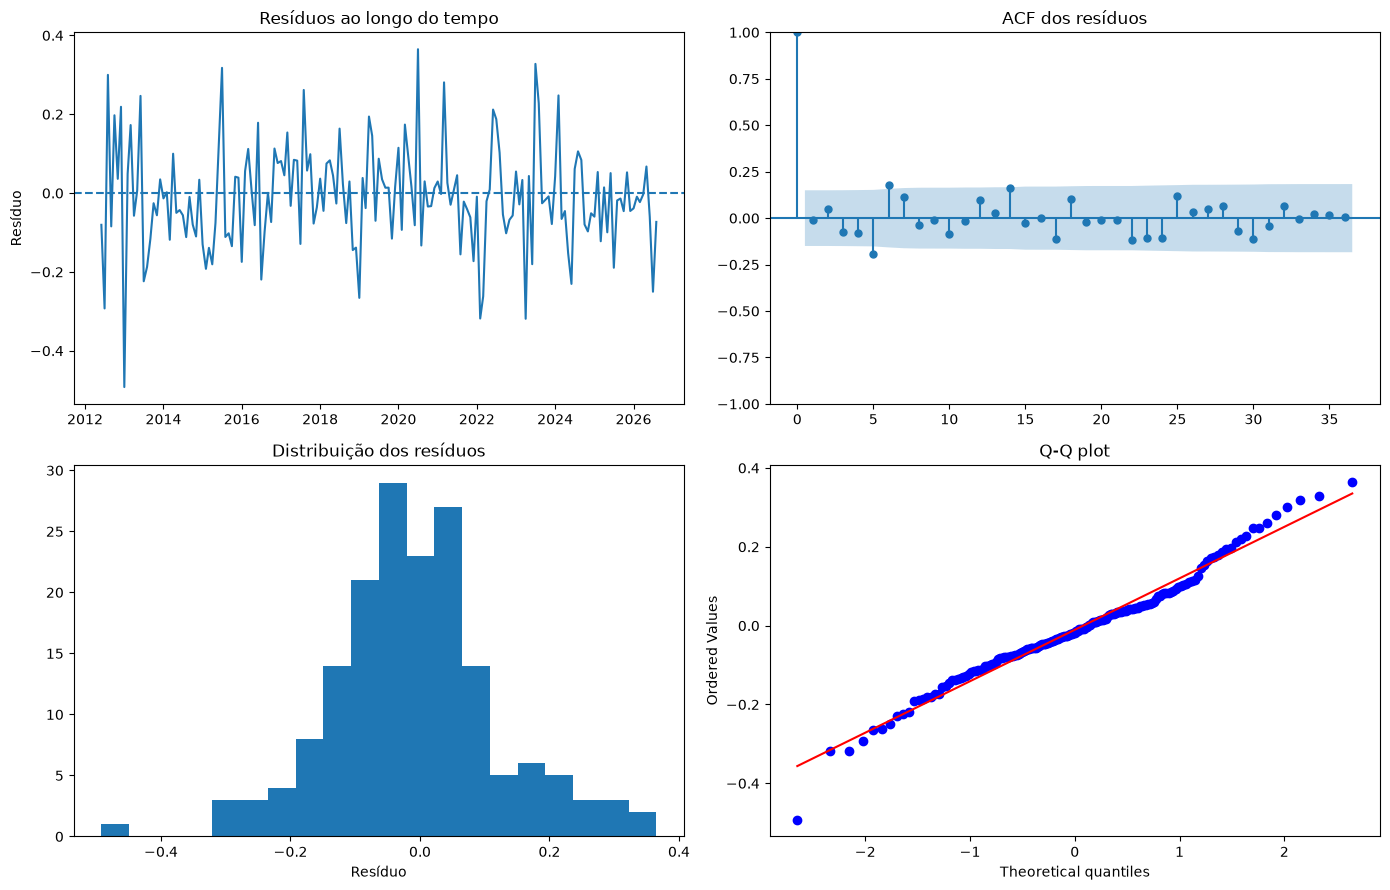

Ljung-Box:
      lb_stat  lb_pvalue
12  20.538670   0.008479
24  37.836791   0.009271

ARCH LM: estatística=7.171, p-valor=0.8461
Jarque-Bera: estatística=9.087, p-valor=0.0106
Média dos resíduos: -0.0105
Desvio-padrão dos resíduos: 0.1307


In [192]:
result = fitted_final["result"]

# Resíduos do ajuste
residuals = pd.Series(
    np.asarray(result.resid, dtype=float),
    index=train_final.index[-len(result.resid):],
).dropna()

# Descartar o período inicial indicado pelo Statsmodels, quando aplicável
burn = getattr(result, "loglikelihood_burn", 0)
residuals = residuals.iloc[burn:]

# Visualizações
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Resíduos ao longo do tempo
axes[0, 0].plot(residuals.index, residuals.values)
axes[0, 0].axhline(0, linestyle="--")
axes[0, 0].set_title("Resíduos ao longo do tempo")
axes[0, 0].set_ylabel("Resíduo")

# 2. Autocorrelação
plot_acf(
    residuals,
    lags=min(36, len(residuals) // 2 - 1),
    ax=axes[0, 1],
)
axes[0, 1].set_title("ACF dos resíduos")

# 3. Distribuição dos resíduos
axes[1, 0].hist(residuals, bins=20)
axes[1, 0].set_title("Distribuição dos resíduos")
axes[1, 0].set_xlabel("Resíduo")

# 4. Gráfico Q-Q
probplot(residuals, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q plot")

plt.tight_layout()
plt.show()

# Testes estatísticos
ljung_box = acorr_ljungbox(
    residuals,
    lags=[12, 24],
    model_df=4,
    return_df=True,
)

arch_stat, arch_pvalue, _, _ = het_arch(
    residuals,
    nlags=12,
)

jb_stat, jb_pvalue = jarque_bera(residuals)

print("Ljung-Box:")
print(ljung_box)

print(f"\nARCH LM: estatística={arch_stat:.3f}, p-valor={arch_pvalue:.4f}")
print(f"Jarque-Bera: estatística={jb_stat:.3f}, p-valor={jb_pvalue:.4f}")
print(f"Média dos resíduos: {residuals.mean():.4f}")
print(f"Desvio-padrão dos resíduos: {residuals.std():.4f}")

A análise dos resíduos foi realizada para avaliar se o modelo SARIMAX(1, 1, 1) × (1, 0, 1, 12), com a taxa Selic como variável exógena, conseguiu capturar adequadamente a estrutura temporal da série de concessões de crédito rural para pessoas físicas.

O teste de Ljung–Box apresentou p-valores inferiores a 0,05 nos lags 12 e 24, indicando evidências de autocorrelação residual. Esse resultado sugere que o modelo não capturou completamente toda a dependência temporal presente na série. Por outro lado, o teste ARCH não apresentou evidências de heterocedasticidade condicional, enquanto o teste de Jarque–Bera indicou desvio da hipótese de normalidade dos resíduos.

Embora a função de autocorrelação possa não apresentar picos individuais expressivos, o teste de Ljung–Box avalia conjuntamente as autocorrelações até determinado lag, podendo detectar dependências distribuídas entre várias defasagens. Da mesma forma, desvios moderados da normalidade não implicam, isoladamente, que o modelo seja inadequado para produzir previsões pontuais.

Portanto, o diagnóstico indica que o modelo apresenta limitações na representação completa da estrutura dos resíduos. Sua utilização é sustentada principalmente pelo desempenho preditivo observado no backtesting e no período de teste final, e não pela hipótese de que os resíduos sejam perfeitamente independentes e normalmente distribuídos.

## Previsões Futuras

,forecast,lower_95,upper_95
date,,,
2026-09-01,17500.38,13652.12,22433.30
2026-10-01,15458.00,11245.83,21247.71
2026-11-01,14016.53,9775.35,20097.62
2026-12-01,13475.35,9114.61,19922.20
2027-01-01,10187.51,6722.62,15437.95
2027-02-01,10585.20,6837.72,16386.22
2027-03-01,12015.51,7613.84,18961.50
2027-04-01,12390.40,7712.58,19905.03
2027-05-01,13236.06,8101.39,21624.70


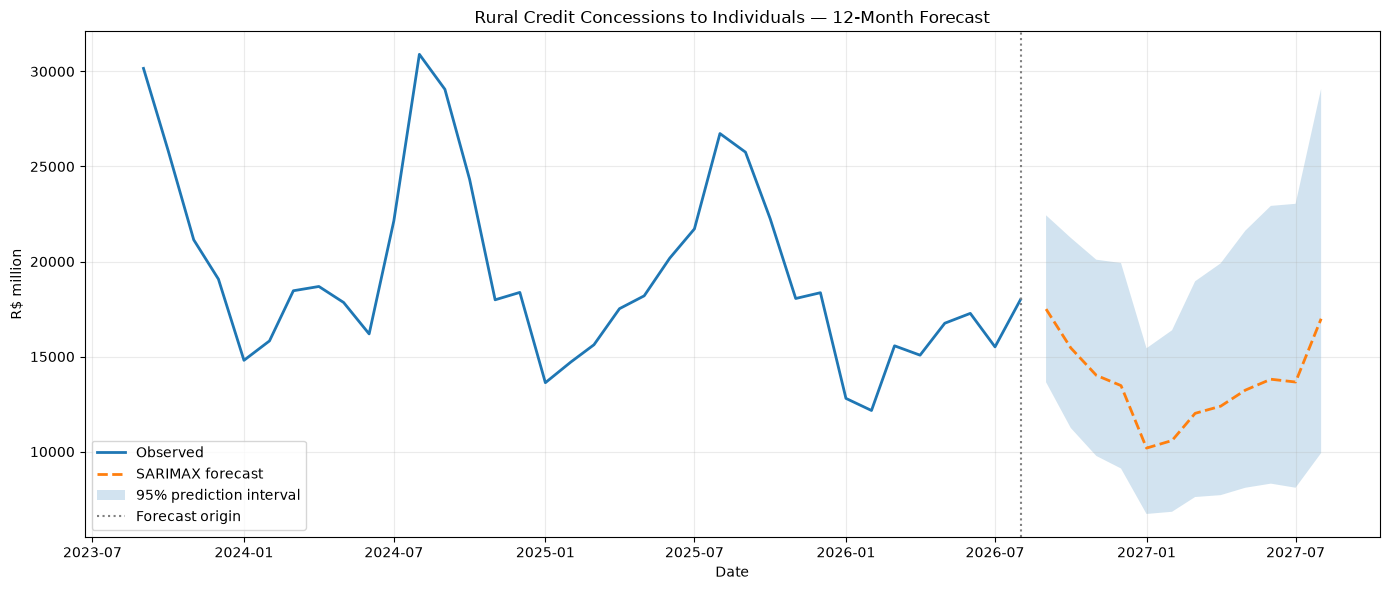

In [199]:
ALPHA = 0.05

target_col = "concessoes_credito_rural_pf"
exog_cols = config["exog"]

# Retrieve the fitted Statsmodels result
result = fitted_final["result"]

# Define the future monthly index
last_date = train_final.index[-1]
freq = pd.infer_freq(train_final.index)

if freq is None:
    freq = "MS"

future_index = pd.date_range(
    start=last_date,
    periods=HORIZON + 1,
    freq=freq,
)[1:]

# Scenario: keep each exogenous variable at its last observed value
future_exog = pd.DataFrame(
    index=future_index,
    columns=exog_cols,
    dtype=float,
)

for col in exog_cols:
    future_exog[col] = train_final[col].iloc[-1]

# Generate forecasts and prediction intervals
forecast_result = result.get_forecast(
    steps=HORIZON,
    exog=future_exog,
)

forecast_mean = forecast_result.predicted_mean
forecast_ci = forecast_result.conf_int(alpha=ALPHA)

# Transform predictions back to the original scale
if USE_LOG:
    forecast_mean = np.expm1(forecast_mean)
    forecast_ci = np.expm1(forecast_ci)

# Build the forecast table
forecast_df = pd.DataFrame(
    {
        "forecast": np.asarray(forecast_mean),
        "lower_95": np.asarray(forecast_ci.iloc[:, 0]),
        "upper_95": np.asarray(forecast_ci.iloc[:, 1]),
    },
    index=future_index,
)

forecast_df.index.name = "date"

# Display forecasts
display(forecast_df.round(2))

# Plot recent history and future forecasts
history_window = 36
history = train_final[target_col].tail(history_window)

plt.figure(figsize=(14, 6))

plt.plot(
    history.index,
    history.values,
    label="Observed",
    linewidth=2,
)

plt.plot(
    forecast_df.index,
    forecast_df["forecast"],
    label="SARIMAX forecast",
    linewidth=2,
    linestyle="--",
)

plt.fill_between(
    forecast_df.index,
    forecast_df["lower_95"].to_numpy(),
    forecast_df["upper_95"].to_numpy(),
    alpha=0.2,
    label="95% prediction interval",
)

plt.axvline(
    last_date,
    linestyle=":",
    linewidth=1.5,
    color="gray",
    label="Forecast origin",
)

plt.title("Rural Credit Concessions to Individuals — 12-Month Forecast")
plt.xlabel("Date")
plt.ylabel("R$ million")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()
